# Proyecto de triaje · IA supervisada y clustering

| Parte | Qué haremos | Requisito |
|---|---|---|
| **A** | Modelo **supervisado** de pretriaje: clasifica al paciente en **crítico** (niveles 1-2), **medio** (nivel 3) o **no crítico** (niveles 4-5). Se entrenan y comparan **cinco modelos**, cada uno en su propio bloque: regresión lineal, regresión logística, KNN, SVM y árbol de decisión | R10, R20, R22 |
| **B** | **Clustering** (no supervisado) de los pacientes reales, interpretación clínica de cada grupo y **aumento de datos dentro de cada grupo** | R07 |

Los datos son los que preparó el biomédico: `triaje_supervisado_limpio.csv`, con 9.304 visitas reales de urgencias de adultos (KTAS de Corea y NHAMCS 2022 de EE. UU.), ya homologadas y con la partición `train`/`test` fija para todo el equipo.

> Este cuaderno **no** usa Docker. Lo que se decida aquí (modelo, umbrales, número de grupos) es lo que empaqueta el servicio `ml`, igual que en la semana 9.

### Resumen de decisiones (se justifican bloque por bloque)
| Decisión | Valor |
|---|---|
| Qué predice | Tres categorías: crítico (1-2), medio (3), no crítico (4-5). El médico la acepta o la rechaza (R10) |
| Modelo | **Regresión logística** con signos de alarma clínicos: la mejor de cinco modelos entrenados y comparados a igual sensibilidad (Bloques 5 a 10) |
| Crítico | P(crítico) ≥ umbral que detecta al menos 7 de cada 10 críticos, **o** red de seguridad (SpO2 < 88 % o PAS < 90 mmHg) |
| No crítico | P(no crítico) alta **y** P(crítico) baja (guarda de seguridad) |
| Alerta en vivo | P(crítico) ≥ umbral con VPP ≥ 0,50, o red de seguridad (R20) |
| Grupos | k-means, k = 5, con edad, FC, FR, PAM, temperatura y SpO2 |
| Aumento | 200 sintéticos desde el conjunto de prueba, dentro de cada grupo y nivel |

## Bloque 0 · Preparación

El cuaderno busca solo la raíz del proyecto (la carpeta que tiene `docker-compose.yml`), así que funciona en cualquier computador sin cambiar rutas. Necesita `pandas`, `numpy`, `scikit-learn` y `matplotlib`.

In [2]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (adjusted_rand_score, balanced_accuracy_score, brier_score_loss, cohen_kappa_score,
                             confusion_matrix, davies_bouldin_score, f1_score, log_loss, roc_auc_score,
                             silhouette_samples, silhouette_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
SEMILLA = 42


def raiz_proyecto():
    # Sube desde la carpeta actual hasta encontrar el docker-compose.yml del proyecto
    for carpeta in [Path.cwd(), *Path.cwd().parents]:
        if (carpeta / "docker-compose.yml").exists():
            return carpeta
    raise FileNotFoundError("Abre el cuaderno dentro de la carpeta del proyecto (proyecto-triage)")


RAIZ = raiz_proyecto()
DATOS = RAIZ / "back" / "preprocesamiento" / "triaje_supervisado_limpio.csv"
HOMOLOGADO = next(RAIZ.rglob("triaje_homologado.csv"), None)   # solo para comparar con el experto (Bloque 14)
SALIDA = RAIZ / "back" / "preprocesamiento" / "salida_ia"
SALIDA.mkdir(exist_ok=True)

AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8a85"
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({"figure.figsize": (7, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "font.size": 10})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 170)
print("Datos:", DATOS.exists(), "| Homologado (experto KTAS):", HOMOLOGADO is not None)

Datos: True | Homologado (experto KTAS): True


# Parte A · Modelo supervisado de pretriaje

## Bloque 1 · Los datos y las tres categorías

| Tipo de columna | Columnas |
|---|---|
| **Predictores** (12) | `edad`, `sexo`, `llegada_ambulancia`, `lesion`, `fc`, `fr`, `pas`, `pad`, `temp_c`, `spo2`, `dolor_nrs`, `motivo_categoria` |
| **Etiqueta original** | `y_triaje`: nivel de triaje de enfermería, de 1 (más urgente) a 5 |
| **No son predictores** | `fuente` (el país), `y_emergencia`, `y_hospitalizado`, `split` |

Agrupamos los cinco niveles en las **tres categorías que verá el médico**:

| Categoría | Niveles | Significado clínico (KTAS y ESI) |
|---|---|---|
| **Crítico** | 1 y 2 | Reanimación o emergencia: valoración inmediata o en minutos |
| **Medio** | 3 | Urgente: requiere atención, pero puede esperar un poco |
| **No crítico** | 4 y 5 | Menos urgente o no urgente |

Ninguno de los 12 predictores identifica a la persona (lo exige R12).

In [3]:
CATEGORIAS = ["crítico", "medio", "no crítico"]          # códigos 0, 1, 2 (de más a menos urgente)


def categoria_de_nivel(nivel):
    return np.where(nivel <= 2, 0, np.where(nivel == 3, 1, 2))


d = pd.read_csv(DATOS)
d["sexo_M"] = (d["sexo"] == "M").astype(int)
d["motivo_categoria"] = d["motivo_categoria"].fillna("otros")
d["categoria"] = categoria_de_nivel(d["y_triaje"].values)

train = d[d["split"] == "train"].reset_index(drop=True)
test = d[d["split"] == "test"].reset_index(drop=True)
print(f"Total {len(d)}  |  entrenamiento {len(train)}  |  prueba {len(test)}")

tabla = pd.crosstab(d["fuente"], d["categoria"].map(dict(enumerate(CATEGORIAS))), normalize="index").mul(100).round(1)
tabla = tabla[CATEGORIAS]
tabla["n"] = d["fuente"].value_counts()
tabla

Total 9304  |  entrenamiento 7443  |  prueba 1861


categoria,crítico,medio,no crítico,n
fuente,,,,
KTAS_Corea,17.4,35.9,46.7,1226
NHAMCS_EEUU_2022,18.5,55.1,26.3,8078


El 18 % de los pacientes es crítico, la mitad es medio y el 29 % es no crítico. Corea tiene más pacientes no críticos que EE. UU.: las dos escalas se parecen, pero no son idénticas. Lo tendremos en cuenta al medir el sesgo.

## Bloque 2 · Sin indicadores de faltante

El preprocesado del biomédico agrega columnas como `spo2_faltante`. Aquí tienen un problema: **el patrón de faltantes depende del país**, no del paciente. Si entran al modelo, este aprende a reconocer el país, y como en Corea hay menos urgencias, aprendería "si falta la SpO2, es menos urgente". Comprobémoslo:

In [4]:
faltantes = pd.DataFrame({
    "spo2_faltante": train["spo2"].isna().astype(int),
    "dolor_nrs_faltante": train["dolor_nrs"].isna().astype(int),
    "lesion_faltante": train["lesion"].isna().astype(int),
})
print((faltantes.groupby(train["fuente"]).mean() * 100).round(1))
es_corea = (train["fuente"] == "KTAS_Corea").astype(int)
prob = cross_val_predict(LogisticRegression(), faltantes, es_corea, cv=5, method="predict_proba")[:, 1]
print(f"\nAUC para adivinar el PAÍS solo con los indicadores de faltante: {roc_auc_score(es_corea, prob):.3f}")

                  spo2_faltante  dolor_nrs_faltante  lesion_faltante
fuente                                                              
KTAS_Corea                 53.5                 0.3              0.0
NHAMCS_EEUU_2022            1.3                24.9              6.3

AUC para adivinar el PAÍS solo con los indicadores de faltante: 0.801


Con un AUC de 0,80 usando solo tres columnas, queda claro que delatan el país. **Decisión:** no las usamos; los faltantes se imputan con la mediana del entrenamiento.

## Bloque 3 · Signos de alarma: el conocimiento clínico como variables

Un modelo lineal supone que cada variable empuja la urgencia **en línea recta**: más FC, siempre un poco más urgente. El triaje real no funciona así. KTAS y ESI usan **zonas de peligro**: por debajo de cierta saturación, o por encima de cierta frecuencia, el paciente sube de nivel de golpe, y algunos signos son peligrosos en los dos extremos. Por eso agregamos **signos de alarma** con los cortes de las guías de triaje:

| Variable | Corte | Por qué |
|---|---|---|
| `spo2_baja` | SpO2 < 92 % | Hipoxemia |
| `fr_alterada` | FR ≥ 24 o < 10 rpm | Dificultad respiratoria o depresión respiratoria |
| `fc_alta`, `fc_baja` | FC ≥ 110, < 50 lpm | Taquicardia o bradicardia |
| `pas_baja`, `pas_muy_alta` | PAS < 90, ≥ 200 mmHg | Hipotensión o crisis hipertensiva |
| `fiebre`, `hipotermia` | ≥ 38 °C, < 35,5 °C | Respuesta inflamatoria o exposición |
| `choque` | FC / PAS ≥ 1 (índice de shock) | Marcador clásico de hipoperfusión |
| `dolor_intenso` | ≥ 7 / 10 | Criterio de prioridad en KTAS |
| `mayor_65` | ≥ 65 años | Factor de riesgo |

**Por qué solo 11.** En una versión anterior probamos 16, con variantes más extremas (SpO2 < 88, FC ≥ 130, FR ≥ 30) y un conteo de alarmas. El desempeño era el mismo, pero las alarmas redundantes se repartían el peso con signos opuestos, y la explicación llegaba a decir que "FC 140 lpm baja la urgencia". Con 11 alarmas sin redundancia **ninguna explicación es incoherente** (lo comprobamos en el Bloque 16).

> Estos cortes los debe validar el biomédico: son criterio clínico, no algo que aprende el modelo.

In [5]:
NUM = ["edad", "fc", "fr", "pas", "pad", "temp_c", "spo2", "dolor_nrs"]
BIN = ["llegada_ambulancia", "lesion", "sexo_M"]
CAT = ["motivo_categoria"]
PREDICTORES = NUM + BIN + CAT
ALARMAS = ["spo2_baja", "fr_alterada", "fc_alta", "fc_baja", "pas_baja", "pas_muy_alta",
           "fiebre", "hipotermia", "choque", "dolor_intenso", "mayor_65"]


def signos_alarma(X):
    # Un dato faltante NO cuenta como alarma (comparar NaN da False)
    X = pd.DataFrame(X, columns=NUM).astype(float)
    f = pd.DataFrame(index=X.index)
    f["spo2_baja"] = X.spo2 < 92
    f["fr_alterada"] = (X.fr >= 24) | (X.fr < 10)
    f["fc_alta"], f["fc_baja"] = X.fc >= 110, X.fc < 50
    f["pas_baja"], f["pas_muy_alta"] = X.pas < 90, X.pas >= 200
    f["fiebre"], f["hipotermia"] = X.temp_c >= 38, X.temp_c < 35.5
    f["choque"] = X.fc / X.pas >= 1
    f["dolor_intenso"], f["mayor_65"] = X.dolor_nrs >= 7, X.edad >= 65
    return f[ALARMAS].astype(float).values


def preprocesador():
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
        ("bin", SimpleImputer(strategy="most_frequent"), BIN),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
        ("alarma", make_pipeline(FunctionTransformer(signos_alarma), StandardScaler()), NUM),
    ])


def con_modelo(modelo):
    return Pipeline([("prep", preprocesador()), ("modelo", modelo)])


def nombres_columnas(prep):
    # Nombre legible de cada columna que sale del preprocesador (para coeficientes e importancias)
    return NUM + BIN + [f"motivo={c}" for c in prep.named_transformers_["cat"].categories_[0]] + \
        [f"alarma:{a}" for a in ALARMAS]


X_train, y_train = train[PREDICTORES], train["categoria"].values
X_test, y_test = test[PREDICTORES], test["categoria"].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

alarmas_train = pd.DataFrame(signos_alarma(train[NUM]), columns=ALARMAS)
resumen = pd.DataFrame({"% pacientes": alarmas_train.mean() * 100,
                        "% críticos si la tiene": [np.mean(y_train[alarmas_train[a] == 1] == 0) * 100 for a in ALARMAS]})
resumen.round(1).sort_values("% críticos si la tiene", ascending=False)

,% pacientes,% críticos si la tiene
pas_baja,1.0,64.4
fc_baja,0.5,51.3
hipotermia,0.3,50.0
fr_alterada,4.6,46.2
spo2_baja,2.0,44.2
choque,3.7,41.2
pas_muy_alta,1.9,33.8
fc_alta,10.1,30.1
fiebre,1.9,27.5
mayor_65,27.1,25.2


Los cortes tienen sentido: un paciente con PAS < 90 mmHg, bradicardia o SpO2 < 92 % es crítico con mucha más frecuencia que el promedio (18 %).

## Bloque 4 · Cómo vamos a entrenar y medir cada modelo

### Las cuatro métricas clave
Las categorías tienen **orden** y no todos los errores pesan igual: mandar a esperar a un crítico es mucho peor que atender antes a uno leve. A cada modelo le medimos estas cuatro:

| Métrica clave | Qué mide | Por qué importa en triaje | Se busca |
|---|---|---|---|
| **AUC crítico** | Qué tan bien ordena a los críticos por encima del resto (0,5 = azar) | Mide la capacidad del modelo **sin depender de ningún umbral** | Mayor |
| **VPP crítico** | De los que marca como críticos, cuántos lo son de verdad | Si es bajo, hay muchas falsas alarmas y el médico deja de confiar | Mayor |
| **Kappa ponderado** | Acuerdo con la enfermera en las tres categorías, castigando más los errores grandes | Es la métrica estándar para comparar triajes | Mayor |
| **Subtriaje grave** | % de críticos reales que el modelo deja como **no críticos** | **El peor error posible** | Menor |

De apoyo: especificidad, F1 macro, Brier (calidad de las probabilidades) y tiempo de entrenamiento.

### Una comparación justa: todos a la misma sensibilidad
Si a cada modelo lo dejamos con "la categoría más probable", casi ninguno elige "crítico", porque "medio" es la mitad de los datos. Y comparar modelos con sensibilidades distintas es comparar peras con manzanas: uno puede "ganar" solo porque marca a más gente. Por eso a **todos** les aplicamos la misma regla:

1. **Crítico** si P(crítico) ≥ `u`, con `u` el umbral más alto que todavía detecta **al menos el 70 % de los críticos**. Así la sensibilidad queda fija (≈ 0,70) y la diferencia entre modelos aparece en las falsas alarmas.
2. **No crítico** si P(no crítico) ≥ `v`, con `v` el corte que maximiza el kappa.
3. **Medio**, todo lo demás.

### El procedimiento, igual para los cinco
| Paso | Qué se hace |
|---|---|
| 1 | `GridSearchCV` busca los mejores hiperparámetros con validación cruzada de 5 partes **solo en entrenamiento** (criterio: log-loss, la calidad de las probabilidades) |
| 2 | Con esos hiperparámetros, `cross_val_predict` da una predicción "fuera de pliegue" para cada paciente de entrenamiento: nunca se predice a un paciente con un modelo que lo vio |
| 3 | Se aplica la regla y se calculan las 4 métricas **en cada uno de los 5 pliegues**: media ± desviación |
| 4 | La **prueba no se toca** hasta el Bloque 10, y solo para confirmar |

In [6]:
import time
from sklearn.base import clone


def metricas(y, cat, p_crit=None, probabilidad=True):
    r = {"sens_critica": np.mean(cat[y == 0] == 0), "VPP_critico": np.mean(y[cat == 0] == 0),
         "espec_critica": np.mean(cat[y != 0] != 0), "% marcados críticos": np.mean(cat == 0),
         "sens_no_critico": np.mean(cat[y == 2] == 2),
         "kappa_pond": cohen_kappa_score(y, cat, weights="quadratic"), "f1_macro": f1_score(y, cat, average="macro"),
         "subtriaje": np.mean(cat > y), "critico_como_no_critico": np.mean(cat[y == 0] == 2)}
    if p_crit is not None:
        r["AUC_critico"] = roc_auc_score(y == 0, p_crit)
        r["brier_critico"] = brier_score_loss(y == 0, p_crit) if probabilidad else np.nan
    return r


def regla(p_crit, p_no_crit, u, v, guarda=1.0):
    # crítico si P(crítico) >= u; si no, no crítico si P(no crítico) >= v y P(crítico) < guarda; si no, medio
    return np.where(p_crit >= u, 0, np.where((p_no_crit >= v) & (p_crit < guarda), 2, 1))


def umbral_por_sensibilidad(p_crit, y, objetivo=0.70):
    candidatos = np.round(np.arange(0.05, 0.60, 0.005), 3)
    return max(u for u in candidatos if np.mean(p_crit[y == 0] >= u) >= objetivo)


def mejor_v(p_crit, p_no_crit, y, u, guarda=1.0):
    return max(np.round(np.arange(0.20, 0.80, 0.01), 2),
               key=lambda v: cohen_kappa_score(y, regla(p_crit, p_no_crit, u, v, guarda), weights="quadratic"))


CLAVE = ["AUC_critico", "VPP_critico", "kappa_pond", "critico_como_no_critico"]
ETIQUETA = {"AUC_critico": "AUC crítico", "VPP_critico": "VPP crítico", "kappa_pond": "Kappa ponderado",
            "critico_como_no_critico": "Subtriaje grave", "sens_critica": "Sensibilidad crítica (fija)",
            "espec_critica": "Especificidad crítica", "f1_macro": "F1 macro", "brier_critico": "Brier"}
PLIEGUES = list(cv.split(X_train, y_train))        # los mismos 5 pliegues para todos los modelos
RESULTADOS, OOF, CORTES, MEJORES = {}, {}, {}, {}


def evaluar(nombre, modelo, puntaje, cat, tiempo, probabilidad=True):
    # puntaje: mayor = más probable que sea crítico. Métricas pliegue por pliegue.
    pliegues = pd.DataFrame([metricas(y_train[i], cat[i], puntaje[i], probabilidad) for _, i in PLIEGUES])
    MEJORES[nombre], RESULTADOS[nombre] = modelo, {"pliegues": pliegues, "tiempo_s": tiempo}
    columnas = CLAVE + ["sens_critica", "espec_critica", "f1_macro", "brier_critico"]
    t = pd.DataFrame({"media": pliegues[columnas].mean(), "desviación": pliegues[columnas].std()})
    t.index = [ETIQUETA[c] for c in columnas]
    print(f"{nombre} · entrena con todo el conjunto en {tiempo:.1f} s")
    return t.round(3)


def ajustar(nombre, estimador, rejilla):
    # Pasos 1 y 2: mejores hiperparámetros y predicción fuera de pliegue
    busqueda = GridSearchCV(con_modelo(estimador), rejilla, cv=cv, scoring="neg_log_loss", n_jobs=-1).fit(X_train, y_train)
    inicio = time.perf_counter()
    clone(busqueda.best_estimator_).fit(X_train, y_train)
    tiempo = time.perf_counter() - inicio
    P = cross_val_predict(busqueda.best_estimator_, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)
    u = umbral_por_sensibilidad(P[:, 0], y_train)
    v = mejor_v(P[:, 0], P[:, 2], y_train, u)
    OOF[nombre], CORTES[nombre] = P, {"u": u, "v": v}
    print("Mejores hiperparámetros:", {k.replace("modelo__", ""): p for k, p in busqueda.best_params_.items()},
          f"| umbral crítico u = {u} | corte no crítico v = {v}")
    return busqueda, P, regla(P[:, 0], P[:, 2], u, v), tiempo


def tabla_rejilla(busqueda):
    r = pd.DataFrame(busqueda.cv_results_)
    params = [c for c in r if c.startswith("param_")]
    r = r[params + ["mean_test_score", "std_test_score"]].rename(
        columns={c: c.replace("param_modelo__", "") for c in params})
    r["log_loss"] = -r.pop("mean_test_score")
    return r.rename(columns={"std_test_score": "desv"}).sort_values("log_loss").round(4)


print("Protocolo listo: metricas(), regla(), ajustar(), evaluar()")

Protocolo listo: metricas(), regla(), ajustar(), evaluar()


## Bloque 5 · Regresión lineal

### Qué es
Ajusta una **recta** (un plano, con muchas variables) que predice un **número**. Aquí le pedimos predecir la categoría como número: 0 = crítico, 1 = medio, 2 = no crítico. Después cortamos ese número en dos puntos para volver a tres categorías.

| Propiedad | Valor |
|---|---|
| **Tipo de problema** | Regresión (valor continuo). Aquí la forzamos a clasificar |
| **Hiperparámetros** | Ninguno; se ajustan los dos cortes |
| **Fortalezas** | La más simple; coeficientes fáciles de leer; entrena al instante |
| **Debilidades** | No da probabilidades; supone que de "crítico" a "medio" hay la misma distancia que de "medio" a "no crítico"; puede predecir valores imposibles (−0,4 o 2,6) |

### Ejemplos de uso en salud
- Estimar la **estancia hospitalaria** en días.
- Predecir la **presión arterial** a partir de edad, IMC y sodio.
- Estimar el **costo** de una atención.

Es el punto de partida: si un modelo más complejo no la supera, no vale la pena.

### Paso 5.1 · Entrenar y predecir fuera de pliegue

In [7]:
lineal = con_modelo(LinearRegression())
inicio = time.perf_counter()
modelo_lineal = clone(lineal).fit(X_train, y_train.astype(float))
tiempo_lineal = time.perf_counter() - inicio

s = cross_val_predict(lineal, X_train, y_train.astype(float), cv=cv)   # puntaje: menor = más urgente
c1 = min(t for t in np.sort(s) if np.mean(s[y_train == 0] <= t) >= 0.70)     # mismo criterio: >= 70 % de críticos
c2 = max(np.quantile(s, np.arange(0.5, 0.98, 0.01)),
         key=lambda c: cohen_kappa_score(y_train, np.digitize(s, [c1 + 1e-9, c]), weights="quadratic"))
cat_lineal = np.digitize(s, [c1 + 1e-9, c2])
OOF["Regresión lineal"], CORTES["Regresión lineal"] = s, {"c1": float(c1), "c2": float(c2)}
print(f"Cortes: crítico si puntaje <= {c1:.3f} · no crítico si puntaje >= {c2:.3f}")

Cortes: crítico si puntaje <= 1.003 · no crítico si puntaje >= 1.316


### Paso 5.2 · Las métricas

In [8]:
evaluar("Regresión lineal", modelo_lineal, -s, cat_lineal, tiempo_lineal, probabilidad=False)

Regresión lineal · entrena con todo el conjunto en 0.0 s


,media,desviación
AUC crítico,0.768,0.015
VPP crítico,0.371,0.012
Kappa ponderado,0.438,0.017
Subtriaje grave,0.088,0.006
Sensibilidad crítica (fija),0.700,0.028
Especificidad crítica,0.734,0.007
F1 macro,0.513,0.016
Brier,NaN,NaN


### Paso 5.3 · Su debilidad, a la vista
Si la regresión lineal fuera buena clasificando, los puntajes de cada categoría real formarían tres montañas separadas.

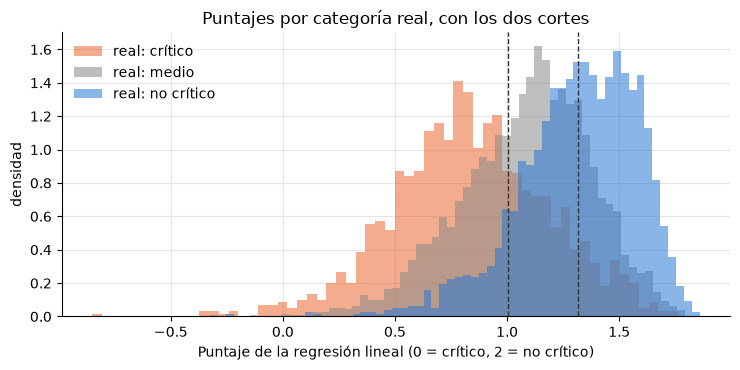

Predicciones fuera del rango posible [0, 2]: 0.3%


In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for c, color in zip(range(3), [NARANJA, GRIS, AZUL]):
    ax.hist(s[y_train == c], bins=60, alpha=0.55, color=color, label=f"real: {CATEGORIAS[c]}", density=True)
for corte in (c1, c2):
    ax.axvline(corte, color="#333", ls="--", lw=1)
ax.set_xlabel("Puntaje de la regresión lineal (0 = crítico, 2 = no crítico)"); ax.set_ylabel("densidad")
ax.set_title("Puntajes por categoría real, con los dos cortes"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print(f"Predicciones fuera del rango posible [0, 2]: {np.mean((s < 0) | (s > 2)):.1%}")

### Cómo leerlo
Las tres montañas se **solapan mucho**: con signos vitales y motivo, un crítico y un medio se parecen. El puntaje ordena razonablemente bien (AUC 0,77, no lejos de los mejores) y tiene el menor subtriaje grave de los cinco (0,089), pero es **solo un número**: no se puede decir "35 % de probabilidad de ser crítico", que es justo lo que el reporte necesita mostrarle al médico, ni construir sobre él la guarda y la alerta de los Bloques 11 y 12. Unas pocas predicciones (0,3 %) caen fuera de 0 a 2, valores que no significan nada clínicamente.

## Bloque 6 · Regresión logística

### Qué es
A pesar del nombre, **clasifica**. Combina las variables como la regresión lineal, pero pasa el resultado por la función logística, que lo convierte en una **probabilidad** entre 0 y 1. Con tres categorías (multinomial) da una probabilidad para cada una, y suman 1.

| Propiedad | Valor |
|---|---|
| **Tipo de problema** | Clasificación |
| **Hiperparámetros** | `C`: inverso de la regularización. `C` pequeño = coeficientes más pequeños, modelo más simple |
| **Fortalezas** | Probabilidades bien calibradas; cada coeficiente se interpreta (odds ratio); rápida; estándar en medicina |
| **Debilidades** | Supone relaciones lineales en el logit (por eso le agregamos los signos de alarma: así capta las "zonas de peligro") |

### Ejemplos de uso en salud
- Escalas de riesgo clínico: **riesgo de reingreso**, **mortalidad en UCI**, **sepsis**.
- Muchas escalas que usan los médicos (puntajes de riesgo cardiovascular, por ejemplo) nacieron de una regresión logística.

### Paso 6.1 · Entrenar con búsqueda de `C`

In [10]:
busqueda_log, P_log, cat_log, tiempo_log = ajustar(
    "Regresión logística", LogisticRegression(max_iter=5000), {"modelo__C": [0.01, 0.1, 1, 10]})
tabla_rejilla(busqueda_log)

Mejores hiperparámetros: {'C': 1} | umbral crítico u = 0.185 | corte no crítico v = 0.38


,C,desv,log_loss
2,1.00,0.009,0.858
3,10.00,0.009,0.858
1,0.10,0.007,0.859
0,0.01,0.005,0.876


### Paso 6.2 · Las métricas

In [11]:
evaluar("Regresión logística", busqueda_log.best_estimator_, P_log[:, 0], cat_log, tiempo_log)

Regresión logística · entrena con todo el conjunto en 0.1 s


,media,desviación
AUC crítico,0.784,0.013
VPP crítico,0.384,0.020
Kappa ponderado,0.437,0.018
Subtriaje grave,0.110,0.005
Sensibilidad crítica (fija),0.703,0.029
Especificidad crítica,0.746,0.013
F1 macro,0.532,0.012
Brier,0.124,0.002


### Paso 6.3 · ¿Cuánto aportan los signos de alarma?
Entrenamos la misma logística **sin** las 11 alarmas para medir qué ganó con el conocimiento clínico del Bloque 3.

In [12]:
sin_alarmas = Pipeline([("prep", ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
    ("bin", SimpleImputer(strategy="most_frequent"), BIN),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])),
    ("modelo", LogisticRegression(max_iter=5000, C=busqueda_log.best_params_["modelo__C"]))])
P_sin = cross_val_predict(sin_alarmas, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)
u_sin = umbral_por_sensibilidad(P_sin[:, 0], y_train)
cat_sin = regla(P_sin[:, 0], P_sin[:, 2], u_sin, mejor_v(P_sin[:, 0], P_sin[:, 2], y_train, u_sin))
pd.DataFrame({"sin alarmas": metricas(y_train, cat_sin, P_sin[:, 0]),
              "con alarmas": metricas(y_train, cat_log, P_log[:, 0])}).loc[CLAVE].rename(index=ETIQUETA).round(3)

,sin alarmas,con alarmas
AUC crítico,0.774,0.783
VPP crítico,0.365,0.384
Kappa ponderado,0.423,0.437
Subtriaje grave,0.100,0.110


### Cómo leerlo
- La regularización casi no cambia el resultado entre `C = 0,1` y `C = 10`: con 7.400 pacientes y ~35 columnas, el modelo no tiene espacio para sobreajustar.
- Las alarmas suben el AUC, el VPP y el kappa: le enseñan a la logística que un signo es peligroso **por encima o por debajo** de un corte, algo que una recta sola no puede representar.
- El subtriaje grave sube un punto (de 0,100 a 0,110) con esta regla simple. Lo corregimos en el Bloque 11 con la **guarda**, algo que solo se puede hacer porque la logística da probabilidades.

## Bloque 7 · K vecinos más cercanos (KNN)

### Qué es
No aprende una fórmula: **guarda a todos los pacientes** de entrenamiento. Para uno nuevo busca los `k` más parecidos y le asigna la proporción de cada categoría entre ellos. "De los 75 pacientes más parecidos a este, 30 fueron críticos": P(crítico) = 0,40.

| Propiedad | Valor |
|---|---|
| **Tipo de problema** | Clasificación o regresión |
| **Hiperparámetros** | `n_neighbors` (k). k pequeño = frontera ruidosa; k grande = frontera suave |
| **Fortalezas** | Intuitivo ("pacientes parecidos"); capta relaciones no lineales sin suponer forma |
| **Debilidades** | Necesita escalar (lo hace el preprocesador); lento al predecir (compara con todos); sufre con muchas variables (en 35 dimensiones "parecido" pierde sentido); probabilidades "gruesas" |

### Ejemplos de uso en salud
- Recomendar tratamientos según **casos similares**.
- **Imputar** valores faltantes con los vecinos (`KNNImputer`).
- Buscar **imágenes parecidas** en un PACS.

### Paso 7.1 · Entrenar con búsqueda de `k`

In [13]:
busqueda_knn, P_knn, cat_knn, tiempo_knn = ajustar(
    "KNN", KNeighborsClassifier(), {"modelo__n_neighbors": [35, 75, 150, 300]})
tabla_rejilla(busqueda_knn)

Mejores hiperparámetros: {'n_neighbors': 75} | umbral crítico u = 0.145 | corte no crítico v = 0.34


,n_neighbors,desv,log_loss
1,75,0.004,0.910
2,150,0.003,0.920
3,300,0.004,0.936
0,35,0.039,1.032


### Paso 7.2 · Las métricas

In [14]:
evaluar("KNN", busqueda_knn.best_estimator_, P_knn[:, 0], cat_knn, tiempo_knn)

KNN · entrena con todo el conjunto en 0.1 s


,media,desviación
AUC crítico,0.729,0.008
VPP crítico,0.288,0.004
Kappa ponderado,0.315,0.023
Subtriaje grave,0.111,0.014
Sensibilidad crítica (fija),0.748,0.021
Especificidad crítica,0.584,0.007
F1 macro,0.452,0.011
Brier,0.136,0.001


### Paso 7.3 · El efecto de `k`
Igual que en la semana 9, vemos cómo cambian las métricas clave con el número de vecinos.

In [15]:
filas = []
for k in [5, 15, 35, 75, 150, 300]:
    P_k = cross_val_predict(con_modelo(KNeighborsClassifier(n_neighbors=k)), X_train, y_train, cv=cv,
                            method="predict_proba", n_jobs=-1)
    u_k = umbral_por_sensibilidad(P_k[:, 0], y_train)
    cat_k = regla(P_k[:, 0], P_k[:, 2], u_k, mejor_v(P_k[:, 0], P_k[:, 2], y_train, u_k))
    m = metricas(y_train, cat_k, P_k[:, 0])
    filas.append({"k": k, **{ETIQUETA[c]: m[c] for c in CLAVE + ["sens_critica"]},
                  "valores distintos de P(crítico)": len(np.unique(P_k[:, 0]))})
pd.DataFrame(filas).set_index("k").round(3)

,AUC crítico,VPP crítico,Kappa ponderado,Subtriaje grave,Sensibilidad crítica (fija),valores distintos de P(crítico)
k,,,,,,
5,0.684,0.268,0.248,0.146,0.724,6
15,0.723,0.265,0.269,0.106,0.804,14
35,0.733,0.321,0.359,0.098,0.711,25
75,0.728,0.288,0.314,0.111,0.748,44
150,0.725,0.291,0.306,0.136,0.726,71
300,0.719,0.283,0.287,0.150,0.710,118


### Cómo leerlo
- Con **k pequeño** el modelo memoriza ruido: con k = 5 el AUC es 0,68. Al subir `k` mejora, pero se estanca alrededor de 0,73, muy por debajo de la logística (0,78).
- `GridSearchCV` eligió k = 75 por log-loss. Con k = 35 el VPP y el kappa son algo mejores, pero sus probabilidades son peores (log-loss 1,03: se equivoca con demasiada seguridad). Con cualquier k, KNN queda lejos de los modelos lineales.
- Con k vecinos, P(crítico) solo puede tomar como máximo k + 1 valores (0/k, 1/k, …). Con k pequeño la sensibilidad "salta" y no se puede ajustar fino al 70 % (con k = 15 queda en 0,80).
- La razón de fondo: con ~35 columnas (signos, motivos, alarmas) la distancia entre pacientes se diluye, y "el paciente más parecido" deja de ser realmente parecido.

## Bloque 8 · Máquina de vectores de soporte (SVM)

### Qué es
Busca la frontera que separa las categorías **con el mayor margen** posible. Con el kernel RBF la frontera puede ser curva. Solo los pacientes cerca de la frontera (los **vectores de soporte**) definen el modelo.

| Propiedad | Valor |
|---|---|
| **Tipo de problema** | Clasificación (y regresión con SVR) |
| **Hiperparámetros** | `C`: cuánto castiga los errores. `gamma`: qué tan curva puede ser la frontera |
| **Fortalezas** | Fronteras complejas; buena en problemas con muchas variables |
| **Debilidades** | Lenta con miles de pacientes; **no da probabilidades nativas** (`probability=True` las estima con una calibración interna extra); difícil de explicar |

### Ejemplos de uso en salud
- Clasificar **tumores** a partir de características de imagen.
- Clasificar **señales** (ECG, EEG).
- Datos genómicos con miles de variables.

### Paso 8.1 · Entrenar con búsqueda de `C` y `gamma`
> Es el modelo más lento: este paso puede tardar unos 3 minutos.

In [16]:
busqueda_svm, P_svm, cat_svm, tiempo_svm = ajustar(
    "SVM (RBF)", SVC(probability=True, random_state=SEMILLA),
    {"modelo__C": [1, 3, 10], "modelo__gamma": ["scale", 0.003]})
tabla_rejilla(busqueda_svm)

Mejores hiperparámetros: {'C': 3, 'gamma': 'scale'} | umbral crítico u = 0.17 | corte no crítico v = 0.27


,C,gamma,desv,log_loss
2,3,scale,0.007,0.865
4,10,scale,0.007,0.868
0,1,scale,0.006,0.871
3,3,0.003,0.006,0.880
5,10,0.003,0.006,0.882
1,1,0.003,0.008,0.892


### Paso 8.2 · Las métricas

In [17]:
evaluar("SVM (RBF)", busqueda_svm.best_estimator_, P_svm[:, 0], cat_svm, tiempo_svm)

SVM (RBF) · entrena con todo el conjunto en 14.1 s


,media,desviación
AUC crítico,0.776,0.013
VPP crítico,0.379,0.017
Kappa ponderado,0.438,0.018
Subtriaje grave,0.132,0.031
Sensibilidad crítica (fija),0.704,0.016
Especificidad crítica,0.739,0.020
F1 macro,0.523,0.012
Brier,0.128,0.002


### Paso 8.3 · Vectores de soporte y costo

In [18]:
svm = busqueda_svm.best_estimator_.named_steps["modelo"]
print(f"Vectores de soporte: {svm.n_support_.sum()} de {len(X_train)} pacientes ({svm.n_support_.sum() / len(X_train):.0%})")
print("Por categoría:", dict(zip(CATEGORIAS, svm.n_support_)))
print(f"Tiempo de entrenamiento · SVM: {tiempo_svm:.1f} s · logística: {tiempo_log:.1f} s "
      f"({tiempo_svm / tiempo_log:.0f} veces más)")

Vectores de soporte: 6153 de 7443 pacientes (83%)
Por categoría: {'crítico': np.int32(1348), 'medio': np.int32(2964), 'no crítico': np.int32(1841)}
Tiempo de entrenamiento · SVM: 14.1 s · logística: 0.1 s (101 veces más)


### Cómo leerlo
**El 83 % de los pacientes** termina siendo vector de soporte: no hay una frontera limpia, casi todos están "cerca del borde". Es otra forma de ver lo que dicen todas las métricas: **las categorías se solapan**. La SVM tiene un desempeño cercano al de la logística, pero tarda más de 100 veces más en entrenar, su subtriaje grave es el más variable entre pliegues (0,132 ± 0,031) y **no se puede explicar** al médico: no hay coeficientes que digan qué variable pesó.

## Bloque 9 · Árbol de decisión

### Qué es
Hace **preguntas sí/no encadenadas**: "¿SpO2 < 92?", "¿motivo = conciencia?", "¿edad > 65?". Cada hoja final da la proporción de cada categoría entre los pacientes de entrenamiento que llegaron ahí.

| Propiedad | Valor |
|---|---|
| **Tipo de problema** | Clasificación o regresión |
| **Hiperparámetros** | `max_depth` (cuántas preguntas seguidas) y `min_samples_leaf` (mínimo de pacientes por hoja) |
| **Fortalezas** | Se lee como un protocolo clínico; no necesita escalar; capta interacciones |
| **Debilidades** | **Sobreajusta** si se deja crecer; inestable (otra muestra, otro árbol); probabilidades en "escalones" |

### Ejemplos de uso en salud
- **Protocolos y guías clínicas** (el propio algoritmo de triaje ESI es un árbol de decisión).
- Decidir pruebas diagnósticas según síntomas.

### Paso 9.1 · Entrenar con búsqueda de profundidad y tamaño de hoja

In [19]:
busqueda_arbol, P_arbol, cat_arbol, tiempo_arbol = ajustar(
    "Árbol de decisión", DecisionTreeClassifier(random_state=SEMILLA),
    {"modelo__max_depth": [4, 6, 8, 10, 14, None], "modelo__min_samples_leaf": [50, 100, 200]})
tabla_rejilla(busqueda_arbol).head(8)

Mejores hiperparámetros: {'max_depth': 10, 'min_samples_leaf': 100} | umbral crítico u = 0.145 | corte no crítico v = 0.32


,max_depth,min_samples_leaf,desv,log_loss
10,10,100,0.024,0.901
7,8,100,0.023,0.903
13,14,100,0.017,0.906
16,None,100,0.017,0.906
4,6,100,0.017,0.914
11,10,200,0.018,0.923
17,None,200,0.019,0.924
14,14,200,0.019,0.924


### Paso 9.2 · Las métricas

In [20]:
evaluar("Árbol de decisión", busqueda_arbol.best_estimator_, P_arbol[:, 0], cat_arbol, tiempo_arbol)

Árbol de decisión · entrena con todo el conjunto en 0.1 s


,media,desviación
AUC crítico,0.730,0.037
VPP crítico,0.323,0.024
Kappa ponderado,0.349,0.053
Subtriaje grave,0.187,0.029
Sensibilidad crítica (fija),0.700,0.063
Especificidad crítica,0.670,0.019
F1 macro,0.459,0.022
Brier,0.132,0.005


### Paso 9.3 · El sobreajuste, en una gráfica
Comparamos el AUC crítico **en los mismos pacientes con que se entrenó** contra el AUC **fuera de pliegue**, para varias profundidades. Si la primera sube y la segunda no, el árbol está memorizando.

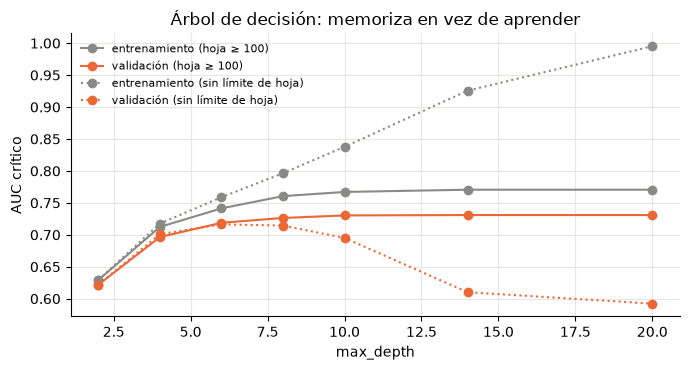

In [21]:
hoja = busqueda_arbol.best_params_["modelo__min_samples_leaf"]
filas = []
for prof in [2, 4, 6, 8, 10, 14, 20]:
    for hoja_i, etiqueta in [(hoja, f"hoja ≥ {hoja}"), (1, "sin límite de hoja")]:
        arbol = con_modelo(DecisionTreeClassifier(max_depth=prof, min_samples_leaf=hoja_i, random_state=SEMILLA))
        p_ent = arbol.fit(X_train, y_train).predict_proba(X_train)[:, 0]
        p_cv = cross_val_predict(arbol, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 0]
        filas.append({"profundidad": prof, "hoja": etiqueta, "AUC entrenamiento": roc_auc_score(y_train == 0, p_ent),
                      "AUC validación": roc_auc_score(y_train == 0, p_cv)})
curva = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(7, 3.8))
for etiqueta, estilo in [(f"hoja ≥ {hoja}", "-"), ("sin límite de hoja", ":")]:
    c = curva[curva["hoja"] == etiqueta]
    ax.plot(c["profundidad"], c["AUC entrenamiento"], estilo, marker="o", color=GRIS, label=f"entrenamiento ({etiqueta})")
    ax.plot(c["profundidad"], c["AUC validación"], estilo, marker="o", color=NARANJA, label=f"validación ({etiqueta})")
ax.set_xlabel("max_depth"); ax.set_ylabel("AUC crítico"); ax.set_title("Árbol de decisión: memoriza en vez de aprender")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

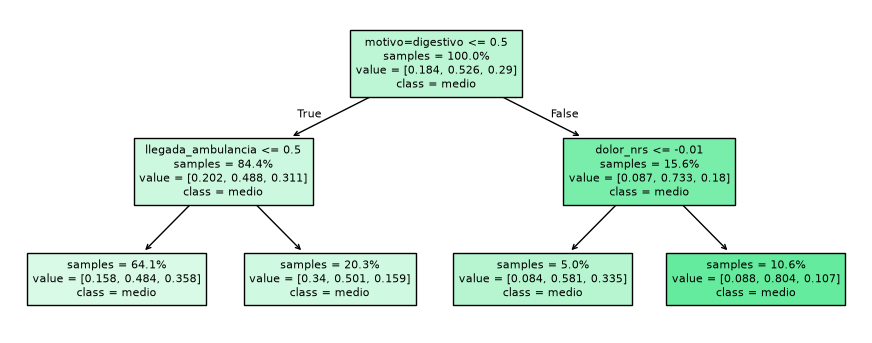

,importancia
motivo=digestivo,0.133
llegada_ambulancia,0.126
motivo=cardiovascular,0.124
edad,0.122
motivo=psiquiatrico_sustancias,0.081
fr,0.071
dolor_nrs,0.060
motivo=genitourinario_gineco,0.053
motivo=neurologico,0.046
fc,0.042


In [22]:
# Las primeras preguntas del árbol (solo 2 niveles, para poder leerlo)
from sklearn.tree import plot_tree

corto = con_modelo(DecisionTreeClassifier(max_depth=2, min_samples_leaf=hoja, random_state=SEMILLA)).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(11, 4.2))
plot_tree(corto.named_steps["modelo"], feature_names=nombres_columnas(corto.named_steps["prep"]),
          class_names=CATEGORIAS, filled=True, impurity=False, proportion=True, fontsize=8, ax=ax)
plt.show()
importancia = pd.Series(busqueda_arbol.best_estimator_.named_steps["modelo"].feature_importances_,
                        index=nombres_columnas(busqueda_arbol.best_estimator_.named_steps["prep"]))
importancia.sort_values(ascending=False).head(10).round(3).to_frame("importancia")

### Cómo leerlo
- **Sin límite de hoja**, el árbol llega a AUC ≈ 1 en entrenamiento mientras la validación **cae** a 0,59: memoriza pacientes. Con hojas de al menos 100 pacientes la validación se estabiliza en ≈ 0,73 desde la profundidad 8, pero no pasa de ahí: queda por debajo de los modelos lineales.
- Sus primeras preguntas tienen lógica clínica: ¿el motivo es digestivo? (el dolor abdominal casi nunca es crítico) y ¿llegó en ambulancia? Es su gran ventaja: **se lee como un protocolo**. (Los cortes de variables numéricas aparecen en unidades estandarizadas porque el árbol recibe los datos ya escalados.)
- Las cuatro hojas dicen "medio": la categoría más frecuente gana en todas. Por eso, en todos los modelos, la categoría no sale del "más probable" sino de **umbrales sobre las probabilidades** (Bloque 4).
- Es el más **inestable**: la mayor desviación entre pliegues en AUC (± 0,037) y kappa (± 0,053), y el peor subtriaje grave (0,187): casi uno de cada cinco críticos queda como no crítico.

## Bloque 10 · Comparar los cinco modelos y elegir

### Paso 10.1 · Las cuatro métricas clave, lado a lado
Mismos pliegues, misma regla, misma sensibilidad (≈ 0,70). Media ± desviación entre los 5 pliegues.

In [23]:
ORDEN = sorted(RESULTADOS, key=lambda n: -RESULTADOS[n]["pliegues"]["VPP_critico"].mean())
comparacion = pd.DataFrame({n: RESULTADOS[n]["pliegues"].mean() for n in ORDEN}).T
desviacion = pd.DataFrame({n: RESULTADOS[n]["pliegues"].std() for n in ORDEN}).T
comparacion["tiempo_s"] = [RESULTADOS[n]["tiempo_s"] for n in ORDEN]

vista = pd.DataFrame({ETIQUETA[c]: [f"{comparacion.loc[n, c]:.3f} ± {desviacion.loc[n, c]:.3f}" for n in ORDEN]
                      for c in CLAVE + ["sens_critica", "espec_critica", "f1_macro"]}, index=ORDEN)
vista["Brier"] = [("—" if np.isnan(comparacion.loc[n, "brier_critico"]) else f"{comparacion.loc[n, 'brier_critico']:.3f}")
                  for n in ORDEN]
vista["Tiempo (s)"] = comparacion["tiempo_s"].round(1)
vista

,AUC crítico,VPP crítico,Kappa ponderado,Subtriaje grave,Sensibilidad crítica (fija),Especificidad crítica,F1 macro,Brier,Tiempo (s)
Regresión logística,0.784 ± 0.013,0.384 ± 0.020,0.437 ± 0.018,0.110 ± 0.005,0.703 ± 0.029,0.746 ± 0.013,0.532 ± 0.012,0.124,0.1
SVM (RBF),0.776 ± 0.013,0.379 ± 0.017,0.438 ± 0.018,0.132 ± 0.031,0.704 ± 0.016,0.739 ± 0.020,0.523 ± 0.012,0.128,14.1
Regresión lineal,0.768 ± 0.015,0.371 ± 0.012,0.438 ± 0.017,0.088 ± 0.006,0.700 ± 0.028,0.734 ± 0.007,0.513 ± 0.016,—,0.0
Árbol de decisión,0.730 ± 0.037,0.323 ± 0.024,0.349 ± 0.053,0.187 ± 0.029,0.700 ± 0.063,0.670 ± 0.019,0.459 ± 0.022,0.132,0.1
KNN,0.729 ± 0.008,0.288 ± 0.004,0.315 ± 0.023,0.111 ± 0.014,0.748 ± 0.021,0.584 ± 0.007,0.452 ± 0.011,0.136,0.1


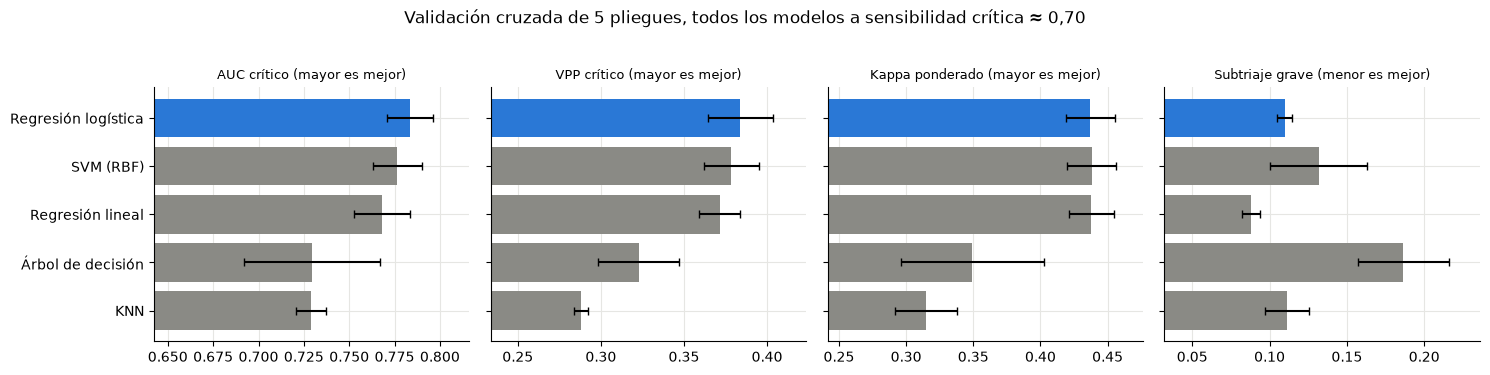

In [24]:
fig, ejes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for eje, c in zip(ejes, CLAVE):
    colores = [AZUL if n == "Regresión logística" else GRIS for n in ORDEN]
    eje.barh(ORDEN, comparacion[c], xerr=desviacion[c], color=colores, capsize=3)
    eje.set_title(ETIQUETA[c] + (" (menor es mejor)" if c == "critico_como_no_critico" else " (mayor es mejor)"),
                  fontsize=9)
    bajo = (comparacion[c] - desviacion[c]).min()
    eje.set_xlim(max(0, bajo - 0.05), (comparacion[c] + desviacion[c]).max() + 0.02)
ejes[0].invert_yaxis()
plt.suptitle("Validación cruzada de 5 pliegues, todos los modelos a sensibilidad crítica ≈ 0,70", y=1.03)
plt.tight_layout(); plt.show()

### Paso 10.2 · ¿La diferencia es real o es suerte del pliegue?
Como todos usan **los mismos pliegues**, podemos comparar pliegue por pliegue: ¿en cuántos de los 5 gana la logística?

In [25]:
log = RESULTADOS["Regresión logística"]["pliegues"]
filas = []
for n in ORDEN:
    if n == "Regresión logística":
        continue
    otro = RESULTADOS[n]["pliegues"]
    filas.append({"logística vs": n,
                  **{f"{ETIQUETA[c]}: gana en": f"{int(((log[c] < otro[c]) if c == 'critico_como_no_critico' else (log[c] > otro[c])).sum())} de 5"
                     for c in CLAVE},
                  "diferencia media de VPP": (log["VPP_critico"] - otro["VPP_critico"]).mean()})
pd.DataFrame(filas).set_index("logística vs").round(3)

,AUC crítico: gana en,VPP crítico: gana en,Kappa ponderado: gana en,Subtriaje grave: gana en,diferencia media de VPP
logística vs,,,,,
SVM (RBF),4 de 5,4 de 5,2 de 5,3 de 5,0.005
Regresión lineal,4 de 5,4 de 5,2 de 5,0 de 5,0.012
Árbol de decisión,5 de 5,5 de 5,5 de 5,5 de 5,0.061
KNN,5 de 5,5 de 5,5 de 5,3 de 5,0.096


### Paso 10.3 · Confirmación en prueba
La elección se hace con validación cruzada. Ahora, **solo para confirmar**, aplicamos cada modelo (entrenado con todo el entrenamiento, con sus umbrales de validación cruzada) a los 1.861 pacientes de prueba. Si el orden se mantiene, la elección no fue suerte. Nada se ajusta con estos números (igual que el `AUC_prueba` de la semana 9).

In [26]:
filas = []
for n in ORDEN:
    m = MEJORES[n]
    if n == "Regresión lineal":
        s_t = m.predict(X_test)
        cat_t, punt_t = np.digitize(s_t, [CORTES[n]["c1"] + 1e-9, CORTES[n]["c2"]]), -s_t
    else:
        P_t = m.predict_proba(X_test)
        cat_t, punt_t = regla(P_t[:, 0], P_t[:, 2], CORTES[n]["u"], CORTES[n]["v"]), P_t[:, 0]
    r = metricas(y_test, cat_t, punt_t, probabilidad=n != "Regresión lineal")
    filas.append({"modelo": n, **{ETIQUETA[c]: r[c] for c in CLAVE + ["sens_critica"]}})
prueba_modelos = pd.DataFrame(filas).set_index("modelo")
prueba_modelos.round(3)

,AUC crítico,VPP crítico,Kappa ponderado,Subtriaje grave,Sensibilidad crítica (fija)
modelo,,,,,
Regresión logística,0.765,0.365,0.417,0.132,0.658
SVM (RBF),0.766,0.366,0.433,0.164,0.673
Regresión lineal,0.743,0.352,0.418,0.099,0.646
Árbol de decisión,0.744,0.335,0.395,0.167,0.734
KNN,0.721,0.301,0.330,0.120,0.743


### Paso 10.4 · La decisión

#### Lo que dicen los números
1. **Hay dos grupos claros.** Arriba, logística, SVM y lineal (AUC 0,77 a 0,78, VPP 0,37 a 0,38, kappa 0,44). Abajo, árbol y KNN (AUC 0,73, VPP 0,29 a 0,32, kappa 0,31 a 0,35): la logística les gana **en los 5 pliegues** en AUC, VPP y kappa, y la prueba lo confirma. **Quedan descartados por desempeño.**
2. **Dentro del grupo de arriba, las diferencias son pequeñas.** La logística tiene el mejor AUC y el mejor VPP en validación cruzada (gana en 4 de 5 pliegues a la SVM y a la lineal), el kappa es un empate (diferencia < 0,002) y la lineal tiene el menor subtriaje grave. En prueba, **logística y SVM empatan** (AUC 0,765 vs 0,766; VPP 0,365 vs 0,366); la SVM saca algo más de kappa, pero con más subtriaje grave (0,164 vs 0,132).
3. Las diferencias dentro del grupo de arriba (≈ 0,01) son menores que la variación entre pliegues (± 0,02). **Por desempeño, los tres son equivalentes.** El techo común (AUC ≈ 0,78) dice que el límite está en **la información** (12 variables de llegada), no en el algoritmo.

#### Cuando el desempeño empata, decide el uso clínico
| Criterio | Regresión lineal | **Regresión logística** | SVM |
|---|---|---|---|
| AUC / VPP crítico (validación cruzada) | 0,768 / 0,371 | **0,784 / 0,384** | 0,776 / 0,379 |
| Kappa ponderado | 0,438 | **0,437** | 0,438 |
| Subtriaje grave con la regla simple | **0,089** | 0,110 | 0,132 ± 0,031 |
| ¿Da probabilidades? | **No**: solo un puntaje | **Sí, calibradas** (Bloque 13) | Estimadas con una calibración extra |
| ¿Permite la guarda y la alerta (Bloques 11 y 12)? | No | **Sí**: con la guarda, el subtriaje grave baja a **0,079**, por debajo de la lineal | Sí |
| ¿Se puede explicar al médico? | Sí | **Sí: un coeficiente por variable** (Bloque 16) | No (caja negra, 83 % de vectores de soporte) |
| Entrenar en el contenedor | Instantáneo | **0,1 s** | 12,7 s (más de 100 veces) |

**Modelo elegido: regresión logística con signos de alarma.** Es la única que reúne las tres cosas que el sistema necesita: el mejor desempeño (empatado en lo alto), **probabilidades confiables** que el reporte puede mostrar y sobre las que se construyen la guarda y la alerta de R20, y una **explicación por variable** que el médico puede revisar antes de aceptar o rechazar la categoría (R10).

> **El mejor modelo no es el más complejo, sino el más simple que resuelve bien el problema y que el equipo clínico puede entender** (semana 9).

## Bloque 11 · La regla de decisión final

En el Bloque 10 todos los modelos usaron una regla simple (umbral crítico + corte no crítico) para compararlos en igualdad. Con la logística elegida, completamos la regla con una **guarda** y una **red de seguridad**, con criterios escritos solo con la validación cruzada:

| Paso | Regla | Criterio |
|---|---|---|
| **1. Crítico** | P(crítico) ≥ `U_CRITICO`, **o** red de seguridad | El umbral más alto que todavía detecta al menos el 70 % de los críticos |
| **2. No crítico** | P(no crítico) ≥ `U_NO_CRITICO` **y** P(crítico) < `GUARDA` | La guarda impide etiquetar "no crítico" a alguien con riesgo apreciable de ser crítico |
| **3. Medio** | Todo lo demás | |
| **Alerta en vivo** (R20) | P(crítico) ≥ `U_ALERTA`, o red de seguridad | El umbral más bajo con VPP ≥ 0,50 de la alerta completa: al menos una de cada dos alertas es un crítico real |

**Red de seguridad:** SpO2 < 88 % o PAS < 90 mmHg. Son signos que ninguna guía de triaje deja esperar, así que el paciente es crítico y dispara la alerta **sin importar la probabilidad**.

¿Por qué dos niveles (categoría crítica y alerta)? La categoría aparece en el reporte que el médico revisa y acepta o rechaza: ahí preferimos no perder críticos. La alerta en vivo interrumpe y exige reconocimiento: si sonara para un tercio de los pacientes, dejaría de tomarse en serio (fatiga de alarmas).

In [27]:
P_cv = OOF["Regresión logística"]
p_crit_cv, p_no_crit_cv = P_cv[:, 0], P_cv[:, 2]


def red_seguridad(X):
    return ((X["spo2"] < 88) | (X["pas"] < 90)).values


seguridad_train = red_seguridad(train)
U_CRITICO = umbral_por_sensibilidad(p_crit_cv, y_train, 0.70)

# Guarda: la más estricta cuyo kappa queda a menos de 0,005 del kappa sin guarda
sin_guarda = cohen_kappa_score(y_train, regla(p_crit_cv, p_no_crit_cv, U_CRITICO,
                                              mejor_v(p_crit_cv, p_no_crit_cv, y_train, U_CRITICO)), weights="quadratic")
filas = []
for g in [1.0, 0.15, 0.12, 0.10, 0.08, 0.06]:
    v = mejor_v(p_crit_cv, p_no_crit_cv, y_train, U_CRITICO, g)
    cat = regla(p_crit_cv, p_no_crit_cv, U_CRITICO, v, g)
    filas.append({"guarda": g, "U_NO_CRITICO": v, "kappa": cohen_kappa_score(y_train, cat, weights="quadratic"),
                  "críticos como no críticos": int(((y_train == 0) & (cat == 2)).sum()),
                  "% de los críticos": np.mean(cat[y_train == 0] == 2), "sens_no_critico": np.mean(cat[y_train == 2] == 2)})
guardas = pd.DataFrame(filas)
elegida = guardas[guardas["kappa"] >= sin_guarda - 0.005].iloc[-1]
GUARDA, U_NO_CRITICO = float(elegida["guarda"]), float(elegida["U_NO_CRITICO"])

candidatos = np.round(np.arange(0.05, 0.60, 0.005), 3)
U_ALERTA = float(min(u for u in candidatos if np.mean(y_train[(p_crit_cv >= u) | seguridad_train] == 0) >= 0.50))

print(f"U_CRITICO = {U_CRITICO}  ·  GUARDA = {GUARDA}  ·  U_NO_CRITICO = {U_NO_CRITICO}  ·  U_ALERTA = {U_ALERTA}")
guardas.round(3)

U_CRITICO = 0.185  ·  GUARDA = 0.1  ·  U_NO_CRITICO = 0.37  ·  U_ALERTA = 0.38


,guarda,U_NO_CRITICO,kappa,críticos como no críticos,% de los críticos,sens_no_critico
0,1.00,0.38,0.437,150,0.110,0.568
1,0.15,0.38,0.438,143,0.105,0.562
2,0.12,0.37,0.437,132,0.097,0.547
3,0.10,0.37,0.435,108,0.079,0.507
4,0.08,0.35,0.423,83,0.061,0.442
5,0.06,0.37,0.399,55,0.040,0.321


La guarda reduce los críticos etiquetados como "no críticos" casi sin costo en el kappa. Sigue quedando un porcentaje pequeño: son críticos con signos completamente normales y un motivo de consulta leve, que el modelo no tiene cómo reconocer. Por eso el reporte siempre lo revisa un médico.

In [28]:
def clasificar(P, X):
    cat = regla(P[:, 0], P[:, 2], U_CRITICO, U_NO_CRITICO, GUARDA)
    return np.where(red_seguridad(X), 0, cat)            # la red de seguridad fuerza "crítico"


def alerta(P, X):
    return (P[:, 0] >= U_ALERTA) | red_seguridad(X)


cat_cv = clasificar(P_cv, train)
pd.DataFrame({"validación cruzada": metricas(y_train, cat_cv, p_crit_cv)}).round(3).T

,sens_critica,VPP_critico,espec_critica,% marcados críticos,sens_no_critico,kappa_pond,f1_macro,subtriaje,critico_como_no_critico,AUC_critico,brier_critico
validación cruzada,0.705,0.383,0.744,0.338,0.506,0.435,0.528,0.15,0.079,0.783,0.124


## Bloque 12 · Evaluación final en prueba, con intervalos de confianza

Ahora evaluamos el modelo elegido **con la regla final completa** (guarda y red de seguridad incluidas) en los 1.861 pacientes que nunca vio. La regla se fijó en el Bloque 11 solo con entrenamiento; en el Bloque 10 la prueba se usó únicamente para confirmar el orden de los modelos. Además del valor puntual calculamos un **intervalo de confianza del 95 %** por bootstrap: remuestreamos la prueba 2.000 veces y vemos cuánto se mueve cada métrica.

In [29]:
modelo_final = clone(MEJORES["Regresión logística"]).fit(X_train, y_train)
P_test = modelo_final.predict_proba(X_test)
p_crit_test = P_test[:, 0]
cat_test = clasificar(P_test, test)
alerta_test = alerta(P_test, test)
real_test = y_test == 0


def resumen_prueba(i):
    m = metricas(y_test[i], cat_test[i], p_crit_test[i])
    a, y = alerta_test[i], y_test[i]
    return {**{k: m[k] for k in ["AUC_critico", "kappa_pond", "f1_macro", "sens_critica", "VPP_critico",
                                 "sens_no_critico", "critico_como_no_critico"]},
            "alerta_sensibilidad": a[y == 0].mean(), "alerta_VPP": (y[a] == 0).mean(), "alerta_%_pacientes": a.mean()}


puntual = resumen_prueba(np.arange(len(y_test)))
rng = np.random.default_rng(0)
boot = pd.DataFrame([resumen_prueba(rng.integers(0, len(y_test), len(y_test))) for _ in range(2000)])
resultado_prueba = pd.DataFrame({"valor": puntual, "IC95_bajo": boot.quantile(0.025), "IC95_alto": boot.quantile(0.975)})
resultado_prueba.round(3)

,valor,IC95_bajo,IC95_alto
AUC_critico,0.765,0.735,0.794
kappa_pond,0.409,0.371,0.448
f1_macro,0.517,0.494,0.539
sens_critica,0.658,0.606,0.707
VPP_critico,0.363,0.325,0.402
sens_no_critico,0.511,0.467,0.553
critico_como_no_critico,0.091,0.061,0.120
alerta_sensibilidad,0.371,0.320,0.423
alerta_VPP,0.502,0.437,0.563
alerta_%_pacientes,0.136,0.120,0.152


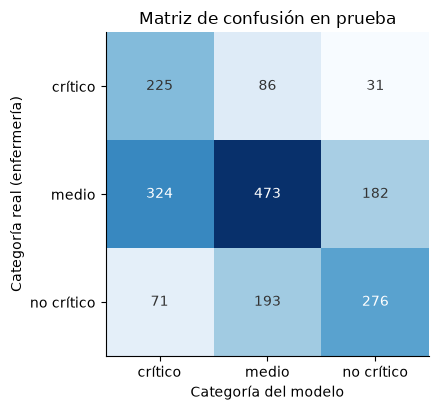

In [30]:
cm = confusion_matrix(y_test, cat_test, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.imshow(cm, cmap="Blues"); ax.grid(False)
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "#333")
ax.set_xticks(range(3), CATEGORIAS); ax.set_yticks(range(3), CATEGORIAS)
ax.set_xlabel("Categoría del modelo"); ax.set_ylabel("Categoría real (enfermería)")
ax.set_title("Matriz de confusión en prueba")
plt.tight_layout(); plt.show()

**Cómo leerla:** la diagonal son los aciertos; arriba de ella está el sobretriaje (más urgencia de la real) y abajo, el subtriaje.

- Dos de cada tres críticos reales quedan como críticos. La casilla clave es **crítico real → no crítico**, el peor error: gracias a la guarda queda en ≈ 9 % de los críticos (sin ella sería mayor). Son críticos con signos normales y motivo leve, que el modelo no tiene cómo reconocer.
- El error más frecuente es **medio → crítico**: sobretriaje. Es el error seguro, y el médico lo corrige al revisar el reporte.
- Los números de prueba quedan algo por debajo de los de validación cruzada, como es normal; no hay una caída grande, así que el modelo generaliza.

## Bloque 13 · ¿Las probabilidades son confiables? (calibración)

Si el reporte dice "35 % de probabilidad de ser crítico", de cada 100 pacientes con ese valor deberían ser críticos más o menos 35. Lo comprobamos por deciles en la prueba:

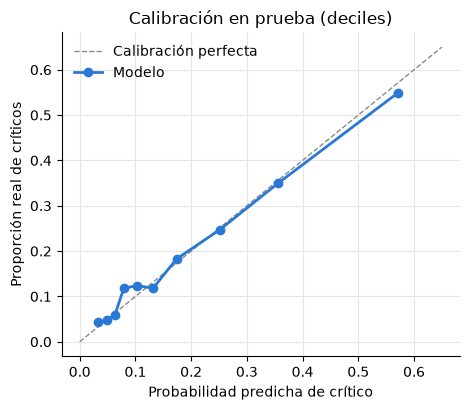

,probabilidad_media,proporcion_real,n
"(0.0132, 0.0424]",0.032,0.043,187
"(0.0424, 0.0562]",0.049,0.048,186
"(0.0562, 0.0703]",0.063,0.059,186
"(0.0703, 0.0898]",0.079,0.118,186
"(0.0898, 0.116]",0.103,0.124,186
"(0.116, 0.148]",0.132,0.118,186
"(0.148, 0.205]",0.174,0.183,186
"(0.205, 0.299]",0.252,0.247,186
"(0.299, 0.423]",0.356,0.349,186
"(0.423, 0.949]",0.570,0.548,186


In [31]:
deciles = pd.qcut(p_crit_test, 10, duplicates="drop")
calib = pd.DataFrame({"p": p_crit_test, "real": real_test}).groupby(deciles, observed=True).agg(
    probabilidad_media=("p", "mean"), proporcion_real=("real", "mean"), n=("real", "size"))
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.plot([0, 0.65], [0, 0.65], color=GRIS, ls="--", lw=1, label="Calibración perfecta")
ax.plot(calib["probabilidad_media"], calib["proporcion_real"], marker="o", color=AZUL, lw=2, label="Modelo")
ax.set_xlabel("Probabilidad predicha de crítico"); ax.set_ylabel("Proporción real de críticos")
ax.set_title("Calibración en prueba (deciles)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
calib.round(3)

Los puntos quedan sobre la diagonal: **las probabilidades se pueden leer tal cual**. Es una ventaja de la regresión logística y la razón por la que el reporte puede mostrarlas al médico.

## Bloque 14 · ¿El modelo aporta algo? Dos comparaciones con referencias clínicas

### 14.1 Contra una regla simple de signos vitales

Una pregunta legítima de un clínico: "¿esto es mejor que mirar los signos vitales?". Comparamos con una regla tipo zona de peligro de ESI (SpO2 < 92, FR ≥ 24 o < 10, FC ≥ 110 o < 50, PAS < 90) y con la misma regla más alteración de conciencia o llegada en ambulancia. Para que sea justo, el modelo marca **el mismo porcentaje de pacientes** que cada regla.

In [32]:
A = pd.DataFrame(signos_alarma(test[NUM]), columns=ALARMAS)
regla_vitales = ((A.spo2_baja + A.fr_alterada + A.fc_alta + A.fc_baja + A.pas_baja) > 0).values
regla_ampliada = regla_vitales | (test["motivo_categoria"] == "conciencia_paro").values | (test["llegada_ambulancia"] == 1).values
filas = []
for nombre, r in [("Regla de signos vitales", regla_vitales), ("Regla + conciencia + ambulancia", regla_ampliada)]:
    modelo_marca = p_crit_test >= np.quantile(p_crit_test, 1 - r.mean())
    for quien, marca in [(nombre, r), ("Modelo (mismo % marcado)", modelo_marca)]:
        filas.append({"comparación": nombre, "quién": quien, "% marcados": marca.mean(),
                      "sensibilidad": marca[real_test].mean(), "especificidad": (~marca[~real_test]).mean(),
                      "VPP": real_test[marca].mean()})
pd.DataFrame(filas).set_index(["comparación", "quién"]).round(3)

% marcados  sensibilidad  especificidad    VPP
comparación                     quién                                                                          
Regla de signos vitales         Regla de signos vitales               0.153         0.266          0.872  0.319
                                Modelo (mismo % marcado)              0.153         0.412          0.905  0.495
Regla + conciencia + ambulancia Regla + conciencia + ambulancia       0.337         0.556          0.712  0.303
                                Modelo (mismo % marcado)              0.337         0.670          0.737  0.365

Marcando la misma cantidad de pacientes, **el modelo encuentra muchos más críticos que las reglas**: el motivo de consulta, la edad y la combinación de signos aportan información que una regla de umbrales no captura.

### 14.2 Contra el triaje **experto** (solo Corea)

KTAS trae, además del triaje de la enfermera, un triaje de **referencia hecho por expertos**: la mejor aproximación a la "verdad" que tenemos. Emparejamos a los pacientes coreanos de prueba con esa columna.

In [33]:
if HOMOLOGADO is None:
    print("No se encontró triaje_homologado.csv en el proyecto: se omite esta comparación.")
else:
    h = pd.read_csv(HOMOLOGADO)
    claves = ["edad", "sexo", "fc", "fr", "pas", "pad", "temp_c", "spo2", "dolor_nrs", "motivo_categoria"]
    k = h[(h["fuente"] == "KTAS_Corea") & (h["edad"] >= 18)][claves + ["triaje_enfermeria", "triaje_experto"]]
    corea = (test["fuente"] == "KTAS_Corea").values
    kt = test[corea].assign(cat_modelo=cat_test[corea], p_crit=p_crit_test[corea])
    m = kt.merge(k.drop_duplicates(subset=claves, keep=False), on=claves)
    m = m[m["triaje_enfermeria"] == m["y_triaje"]]
    e = categoria_de_nivel(m["triaje_experto"].astype(int).values)
    n = m["categoria"].values
    mo = m["cat_modelo"].values
    print(f"Pacientes coreanos de prueba emparejados con el experto: {len(m)}\n")
    print(pd.DataFrame({
        "kappa ponderado vs experto": [cohen_kappa_score(n, e, weights="quadratic"), cohen_kappa_score(mo, e, weights="quadratic")],
        "subtriaje vs experto": [np.mean(n > e), np.mean(mo > e)],
        "sensibilidad crítica (experto)": [np.mean(n[e == 0] == 0), np.mean(mo[e == 0] == 0)],
    }, index=["Enfermera", "Modelo"]).round(3))
    print(f"\nAUC crítico del modelo  ·  según la enfermera: {roc_auc_score(n == 0, m['p_crit']):.3f}"
          f"  ·  según el experto: {roc_auc_score(e == 0, m['p_crit']):.3f}")

Pacientes coreanos de prueba emparejados con el experto: 243

           kappa ponderado vs experto  subtriaje vs experto  sensibilidad crítica (experto)
Enfermera                       0.898                 0.062                           0.927
Modelo                          0.520                 0.066                           0.829

AUC crítico del modelo  ·  según la enfermera: 0.842  ·  según el experto: 0.875


- **La enfermera coincide más con el experto que el modelo** y detecta más críticos, como era de esperar: ella ve al paciente completo.
- Pero **el modelo ordena mejor a los críticos según el experto que según la enfermera**: parte de lo que contamos como "error del modelo" son discrepancias de la etiqueta de enfermería.

> Es una muestra pequeña (≈ 240 pacientes coreanos): sirve como evidencia de apoyo, no como conclusión definitiva.

## Bloque 15 · Sesgo por subgrupo

Un buen promedio puede esconder a un grupo al que el modelo le falla. Medimos por país, sexo y edad (R22 lo exige).

In [34]:
t = test.assign(p_critico=p_crit_test, cat=cat_test,
                grupo_edad=pd.cut(test["edad"], [17, 39, 64, 120], labels=["18-39", "40-64", "65+"]))
filas = []
for columna in ["fuente", "sexo", "grupo_edad"]:
    for valor, g in t.groupby(columna, observed=True):
        y, c = g["categoria"].values, g["cat"].values
        filas.append({"variable": columna, "grupo": valor, "n": len(g), "% críticos": np.mean(y == 0),
                      "AUC_critico": roc_auc_score(y == 0, g["p_critico"]),
                      "sens_critica": np.mean(c[y == 0] == 0), "espec_critica": np.mean(c[y != 0] != 0),
                      "kappa": cohen_kappa_score(y, c, weights="quadratic"),
                      "critico_como_no_critico": np.mean(c[y == 0] == 2)})
sesgo = pd.DataFrame(filas)
sesgo.round(3)

,variable,grupo,n,% críticos,AUC_critico,sens_critica,espec_critica,kappa,critico_como_no_critico
0,fuente,KTAS_Corea,246,0.175,0.845,0.791,0.719,0.496,0.047
1,fuente,NHAMCS_EEUU_2022,1615,0.185,0.754,0.639,0.743,0.394,0.097
2,sexo,F,979,0.143,0.751,0.643,0.760,0.368,0.093
3,sexo,M,882,0.229,0.766,0.668,0.715,0.445,0.089
4,grupo_edad,18-39,683,0.129,0.750,0.489,0.857,0.373,0.205
5,grupo_edad,40-64,672,0.186,0.756,0.688,0.739,0.426,0.064
6,grupo_edad,65+,506,0.255,0.747,0.744,0.557,0.276,0.039


### Hallazgos que hay que reportar

- **La capacidad de ordenar (AUC) es parecida en todos los grupos**: el modelo no "ve peor" a ningún grupo.
- **Pero la sensibilidad cae en jóvenes (18 a 39 años)**: como la edad aumenta la probabilidad de crítico, un joven crítico con signos estables queda por debajo del umbral más seguido, y **uno de cada cinco críticos jóvenes queda como "no crítico"**. Es la limitación más importante del modelo. **En jóvenes, el criterio del médico pesa más que el modelo.**
- **En adultos mayores** se detectan más críticos, con más falsas alarmas.
- **Por país**, el modelo discrimina mejor en Corea; la muestra coreana es pequeña (≈ 250 en prueba).

Una mejora futura sería usar umbrales distintos por grupo de edad, pero es una decisión clínica y ética del equipo, no del modelo.

> **Limitación de la etiqueta:** el modelo imita el triaje **de enfermería**. Apoya la decisión; no la reemplaza.

## Bloque 16 · ¿Qué aprendió el modelo?

La regresión logística tiene un coeficiente por variable y por categoría. Como las variables están estandarizadas, se pueden comparar. Resumimos cuánto empuja cada una hacia **crítico** frente a las otras dos categorías: es lo que el reporte le mostrará al médico como factores.

In [35]:
prep = modelo_final.named_steps["prep"]
nombres = nombres_columnas(prep)
coef = modelo_final.named_steps["modelo"].coef_
peso = pd.Series(coef[0] - coef[1:].mean(axis=0), index=nombres, name="hacia_critico")
pd.concat([peso.sort_values(ascending=False).head(12), peso.sort_values().head(8)]).round(2).to_frame()

,hacia_critico
motivo=conciencia_paro,1.89
motivo=cardiovascular,1.47
motivo=psiquiatrico_sustancias,1.34
llegada_ambulancia,0.79
motivo=neurologico,0.42
edad,0.34
alarma:pas_baja,0.21
dolor_nrs,0.17
alarma:fr_alterada,0.17
motivo=respiratorio,0.16


In [36]:
# Verificación: en el reporte, cada signo vital se explica JUNTO con sus alarmas (el servicio ml hace lo mismo).
# Comprobamos en toda la prueba que un signo vital CON alarma nunca aparezca "bajando" la urgencia.
GRUPOS = {"fc": ["fc_alta", "fc_baja"], "fr": ["fr_alterada"], "pas": ["pas_baja", "pas_muy_alta"],   # la PAS va con la PAD
          "temp_c": ["fiebre", "hipotermia"], "spo2": ["spo2_baja"], "edad": ["mayor_65"], "dolor_nrs": ["dolor_intenso"]}
aporte = pd.DataFrame(prep.transform(X_test) * peso.values, columns=nombres)
alarmas_test = pd.DataFrame(signos_alarma(test[NUM]), columns=ALARMAS)
total = incoherentes = 0
for vital, alarmas_v in GRUPOS.items():
    tiene = alarmas_test[alarmas_v].sum(axis=1).values > 0
    neto = aporte[vital] + (aporte["pad"] if vital == "pas" else 0) + aporte[[f"alarma:{a}" for a in alarmas_v]].sum(axis=1)
    total += tiene.sum(); incoherentes += (tiene & (neto.values < 0)).sum()
print(f"Signos vitales con alarma en prueba: {total}  ·  explicados como 'bajan la urgencia': {incoherentes}")

Signos vitales con alarma en prueba: 1445  ·  explicados como 'bajan la urgencia': 0


Lo que más empuja hacia crítico es el **motivo de consulta** (alteración de conciencia, cardiovascular, psiquiátrico, neurológico), la **llegada en ambulancia** y los **signos de alarma**. Lo que aleja son los motivos de ojos, oído y boca, piel y trauma menor. Todo tiene sentido clínico: el modelo aprende **cómo triaja la enfermera**, y la enfermera se guía mucho por el motivo y por los signos de peligro.

## Bloque 17 · Tres pacientes de ejemplo

R20 pide declarar en el contrato (`paciente_critico`) valores que **garanticen** la alerta. Probamos un paciente crítico, uno intermedio y uno leve:

In [37]:
ejemplos = pd.DataFrame([
    dict(edad=70, fc=140, fr=32, pas=75, pad=40, temp_c=36.5, spo2=82, dolor_nrs=0,
         llegada_ambulancia=1, lesion=0, sexo_M=1, motivo_categoria="conciencia_paro"),
    dict(edad=52, fc=96, fr=20, pas=150, pad=92, temp_c=37.2, spo2=96, dolor_nrs=6,
         llegada_ambulancia=0, lesion=0, sexo_M=0, motivo_categoria="digestivo"),
    dict(edad=30, fc=78, fr=16, pas=120, pad=75, temp_c=36.6, spo2=99, dolor_nrs=3,
         llegada_ambulancia=0, lesion=1, sexo_M=0, motivo_categoria="musculoesqueletico"),
], index=["paciente 1", "paciente 2", "paciente 3"])
P_ej = modelo_final.predict_proba(ejemplos[PREDICTORES])
res = pd.DataFrame(P_ej, index=ejemplos.index, columns=[f"P({c})" for c in CATEGORIAS])
res["categoría"] = [CATEGORIAS[c] for c in clasificar(P_ej, ejemplos)]
res["alerta"] = alerta(P_ej, ejemplos)
res.round(3)

,P(crítico),P(medio),P(no crítico),categoría,alerta
paciente 1,0.986,0.014,0.000,crítico,True
paciente 2,0.085,0.764,0.151,medio,False
paciente 3,0.018,0.245,0.737,no crítico,False


El paciente 1 es crítico con una probabilidad muy alta y además activa la red de seguridad (SpO2 82 %, PAS 75): es un candidato seguro para `paciente_critico` en el `tester.yaml`.

# Parte B · Clustering y aumento de datos por grupos (R07)

## Bloque 18 · ¿Qué agrupamos y con qué variables?

Ahora **no** usamos la etiqueta: k-means mira solo las variables clínicas y forma grupos de pacientes parecidos. Los usamos para **entender a la población** (qué perfiles llegan y en cuáles se confunde el modelo) y para **aumentar los datos** dentro de cada perfil.

La elección de variables importa mucho en k-means, porque cada variable pesa lo mismo en la distancia. Comparamos tres opciones:

| Opción | Variables | Problema que resuelve |
|---|---|---|
| A (versión 1) | edad, FC, FR, PAS, PAD, temperatura, SpO2, dolor | — |
| B | Igual, sin dolor | El dolor es **subjetivo** y falta en el 25 % de NHAMCS: al imputarlo con la mediana se crean pacientes artificiales "con dolor 5" |
| C | edad, FC, FR, **PAM**, temperatura, SpO2 | Además, PAS y PAD están correlacionadas (r ≈ 0,6): juntas le dan **doble peso** a la presión. La presión arterial media las resume en una |

No usamos `y_triaje` (dejaría de ser no supervisado) ni `fuente` (agruparía por país).

Para cada opción y cada k medimos la **silueta** (qué tan separados están los grupos), la **estabilidad** (si remuestreamos los pacientes, ¿salen los mismos grupos? Se mide con el índice de Rand ajustado, ARI, donde 1 es idéntico) y la **asociación con el país** (V de Cramér: queremos que sea baja).

In [38]:
train["pam"] = (train["pas"] + 2 * train["pad"]) / 3
test["pam"] = (test["pas"] + 2 * test["pad"]) / 3
OPCIONES = {"A · 8 variables (v1)": ["edad", "fc", "fr", "pas", "pad", "temp_c", "spo2", "dolor_nrs"],
            "B · sin dolor": ["edad", "fc", "fr", "pas", "pad", "temp_c", "spo2"],
            "C · PAM, sin dolor": ["edad", "fc", "fr", "pam", "temp_c", "spo2"]}


def cramer_v(a, b):
    tabla = pd.crosstab(a, b).values
    esperado = np.outer(tabla.sum(1), tabla.sum(0)) / tabla.sum()
    return np.sqrt(((tabla - esperado) ** 2 / esperado).sum() / (tabla.sum() * (min(tabla.shape) - 1)))


rng = np.random.default_rng(0)
filas = []
for opcion, variables in OPCIONES.items():
    Z = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit_transform(train[variables])
    for k in [3, 4, 5, 6]:
        etiquetas = KMeans(k, n_init=10, random_state=SEMILLA).fit_predict(Z)
        aris = []
        for b in range(10):
            idx = rng.choice(len(Z), len(Z), replace=True)
            aris.append(adjusted_rand_score(etiquetas, KMeans(k, n_init=10, random_state=b).fit(Z[idx]).predict(Z)))
        filas.append({"opción": opcion, "k": k,
                      "silueta": silhouette_score(Z, etiquetas, sample_size=4000, random_state=SEMILLA),
                      "estabilidad_ARI": np.mean(aris), "V_país": cramer_v(etiquetas, train["fuente"])})
opciones = pd.DataFrame(filas).set_index(["opción", "k"])
opciones.round(3)

silueta  estabilidad_ARI  V_país
opción               k                                  
A · 8 variables (v1) 3    0.133            0.911   0.135
                     4    0.137            0.918   0.152
                     5    0.129            0.854   0.144
                     6    0.121            0.911   0.210
B · sin dolor        3    0.155            0.798   0.099
                     4    0.162            0.919   0.112
                     5    0.158            0.904   0.105
                     6    0.147            0.851   0.112
C · PAM, sin dolor   3    0.161            0.824   0.109
                     4    0.162            0.905   0.105
                     5    0.165            0.890   0.106
                     6    0.158            0.818   0.105

**Elegimos la opción C con k = 5:**

- Quitar el dolor y usar la PAM **sube la silueta** de ≈ 0,13 a ≈ 0,16 y **baja la asociación con el país**, porque el dolor faltante era sobre todo de EE. UU.
- Los grupos son **estables** (ARI ≈ 0,9): si remuestreamos a los pacientes, salen prácticamente los mismos.
- Las tres opciones producen **los mismos cinco perfiles clínicos** (lo verás en el Bloque 20). Que la estructura aparezca con distintas variables es una buena señal de que es real y no un artefacto.

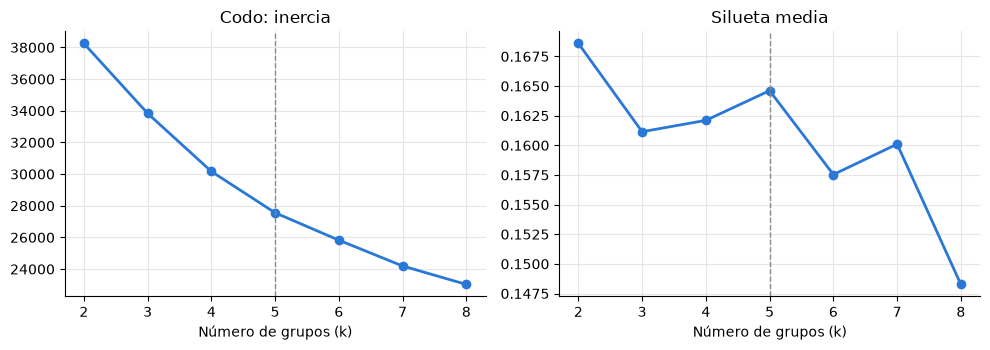

k,2,3,4,5,6,7,8
inercia,38254.000,33836.000,30166.000,27556.000,25825.000,24196.000,23030.000
silueta,0.169,0.161,0.162,0.165,0.158,0.160,0.148
davies_bouldin,2.117,1.812,1.655,1.584,1.562,1.478,1.532


In [39]:
VARS_CLUSTER = OPCIONES["C · PAM, sin dolor"]
escala_cluster = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(train[VARS_CLUSTER])
Z_train = escala_cluster.transform(train[VARS_CLUSTER])

ks = list(range(2, 9))
inercias, siluetas, davies = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z_train)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(Z_train, km.labels_, sample_size=4000, random_state=SEMILLA))
    davies.append(davies_bouldin_score(Z_train, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(ks, inercias, marker="o", color=AZUL, lw=2); ax[0].set_title("Codo: inercia")
ax[1].plot(ks, siluetas, marker="o", color=AZUL, lw=2); ax[1].set_title("Silueta media")
for a in ax:
    a.set_xlabel("Número de grupos (k)"); a.axvline(5, color=GRIS, ls="--", lw=1)
plt.tight_layout(); plt.show()
pd.DataFrame({"k": ks, "inercia": np.round(inercias), "silueta": np.round(siluetas, 3),
              "davies_bouldin": np.round(davies, 3)}).set_index("k").T

## Bloque 19 · Justificación del número de grupos

- **El codo no es marcado:** la inercia baja de forma suave.
- **La silueta es baja para todo k (≈ 0,15 a 0,17).** Es normal en datos clínicos: los pacientes forman un continuo con zonas más densas, no islas separadas.
- **k = 5 es un máximo local de la silueta** (supera a k = 3, 4 y 6). k = 2 tiene una silueta algo mayor, pero solo separa "jóvenes" de "mayores", lo que no sirve clínicamente.
- **Davies-Bouldin** (menor es mejor) baja de forma continua hasta k ≈ 7: no marca un k claro, solo confirma que más de 4 grupos describe mejor a los pacientes que 2 o 3.
- **k = 5 es el menor k en que cada grupo tiene una interpretación clínica distinta**, y sus grupos son estables (ARI ≈ 0,9).

Esta justificación es la que va en `docs/DATASETS.md`.

## Bloque 20 · Interpretación clínica de los grupos

Describimos cada grupo con la **mediana** de sus variables en unidades clínicas (incluidas las que no se usaron para agrupar). Luego, **solo para interpretar**, cruzamos con la etiqueta y con el desempeño del modelo en validación cruzada.

In [40]:
K = 5
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(Z_train)
train["cluster"] = kmeans.labels_

# Los números de k-means son arbitrarios: les damos nombre según su perfil
med = train.groupby("cluster")[NUM].median()
nombre = {med["spo2"].idxmin(): "Compromiso respiratorio"}
for col, fn, etiqueta in [("edad", "idxmin", "Jóvenes con signos estables"), ("pas", "idxmax", "Hipertensión arterial"),
                          ("edad", "idxmax", "Adultos mayores estables")]:
    resto = med.drop(index=list(nombre))
    nombre[getattr(resto[col], fn)()] = etiqueta
nombre[med.drop(index=list(nombre)).index[0]] = "Taquicardia / febril"
train["grupo"] = train["cluster"].map(nombre)

train["acierto"] = cat_cv == y_train
train["subtriaje"] = cat_cv > y_train
train["detectado"] = np.where(y_train == 0, cat_cv == 0, np.nan)

g = train.groupby("grupo")
perfil = g[NUM].median().round(1)
perfil["n"] = g.size()
perfil["% ambulancia"] = (g["llegada_ambulancia"].mean() * 100).round(0)
perfil["% Corea"] = (g["fuente"].apply(lambda s: (s == "KTAS_Corea").mean()) * 100).round(0)
perfil["motivo más común"] = g["motivo_categoria"].agg(lambda s: s.value_counts().index[0])
perfil["% nivel 1-2"] = (g["y_triaje"].apply(lambda s: (s <= 2).mean()) * 100).round(0)
perfil["% nivel 4-5"] = (g["y_triaje"].apply(lambda s: (s >= 4).mean()) * 100).round(0)
perfil["% críticos detectados"] = (g["detectado"].mean() * 100).round(0)
perfil["% subtriaje"] = (g["subtriaje"].mean() * 100).round(0)
perfil["silueta media"] = pd.Series(silhouette_samples(Z_train, kmeans.labels_)).groupby(train["grupo"]).mean().round(3)
perfil["% silueta negativa"] = (pd.Series(silhouette_samples(Z_train, kmeans.labels_) < 0).groupby(train["grupo"]).mean() * 100).round(0)
perfil.sort_values("% nivel 1-2", ascending=False)

,edad,fc,fr,pas,pad,temp_c,spo2,dolor_nrs,n,% ambulancia,% Corea,motivo más común,% nivel 1-2,% nivel 4-5,% críticos detectados,% subtriaje,silueta media,% silueta negativa
grupo,,,,,,,,,,,,,,,,,,
Compromiso respiratorio,56.0,101.0,33.0,130.0,86.0,36.9,88.0,6.0,125,42.0,3.0,respiratorio,50.0,9.0,100.0,0.0,0.044,39.0
Taquicardia / febril,45.0,108.0,18.0,135.0,81.0,37.1,97.0,5.0,1092,25.0,9.0,digestivo,24.0,22.0,73.0,13.0,0.011,50.0
Hipertensión arterial,57.0,88.0,18.0,163.0,97.0,36.7,98.0,5.0,1618,23.0,15.0,digestivo,21.0,25.0,72.0,13.0,0.128,12.0
Adultos mayores estables,69.0,76.0,18.0,131.0,73.0,36.6,97.0,3.0,2090,34.0,18.0,musculoesqueletico,20.0,24.0,73.0,13.0,0.155,6.0
Jóvenes con signos estables,31.0,85.0,18.0,127.0,78.0,36.7,99.0,5.0,2518,14.0,11.0,digestivo,11.0,39.0,56.0,19.0,0.266,0.0


Varianza explicada por las 2 componentes: [0.232 0.214] | total: 0.446


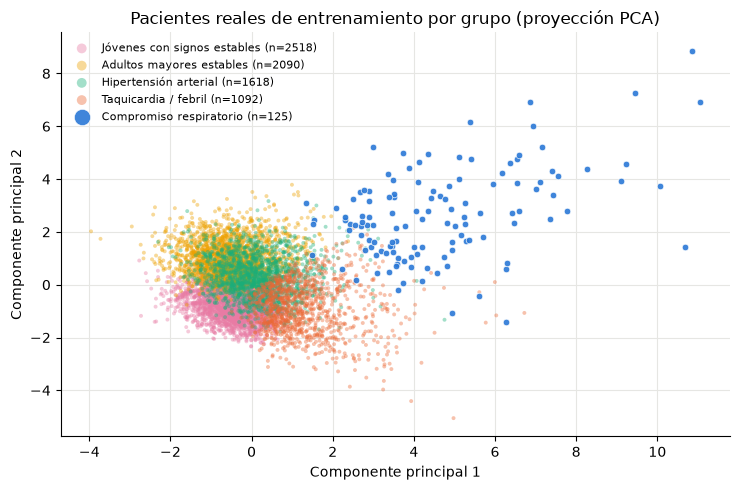

In [41]:
pca = PCA(n_components=2, random_state=SEMILLA).fit(Z_train)
XY = pca.transform(Z_train)
print("Varianza explicada por las 2 componentes:", pca.explained_variance_ratio_.round(3), "| total:", round(pca.explained_variance_ratio_.sum(), 3))
orden = perfil.sort_values("% nivel 1-2", ascending=False).index
color_de = dict(zip(orden, COLORES))
fig, ax = plt.subplots(figsize=(7.5, 5))
for grupo in perfil.sort_values("n", ascending=False).index:      # los grupos pequeños se dibujan encima
    m = (train["grupo"] == grupo).values
    pequeno = m.sum() < 500
    ax.scatter(XY[m, 0], XY[m, 1], s=22 if pequeno else 8, alpha=0.9 if pequeno else 0.4,
               color=color_de[grupo], label=f"{grupo} (n={m.sum()})",
               edgecolors="white" if pequeno else "none", linewidths=0.5)
ax.set_xlabel("Componente principal 1"); ax.set_ylabel("Componente principal 2")
ax.set_title("Pacientes reales de entrenamiento por grupo (proyección PCA)")
ax.legend(markerscale=2.5, fontsize=8, frameon=False, loc="best")
plt.tight_layout(); plt.show()

La proyección PCA aplana 6 variables en 2 y conserva solo el 45 % de la variación: el dibujo es **útil pero incompleto**. El grupo respiratorio se separa con claridad; los otros cuatro se ven solapados porque la diferencia entre ellos está en variables que la proyección no muestra completas (edad, PAM, FC). La tabla de medianas es la que muestra la diferencia real.

### Lectura clínica (para revisar con el biomédico)

| Grupo | Perfil | Lectura |
|---|---|---|
| **Compromiso respiratorio** | SpO2 ≈ 88 %, FR ≈ 33, taquicardia; muchos en ambulancia | El más pequeño y el más grave: la mitad son nivel 1 o 2. El modelo detecta a casi todos sus críticos |
| **Taquicardia / febril** | FC ≈ 108, temperatura algo más alta, ~45 años | Uno de cada cuatro es crítico. La taquicardia sola no basta para separar al crítico |
| **Hipertensión arterial** | PAS ≈ 163, PAD ≈ 97, ~57 años | Uno de cada cinco crítico: la presión alta, por sí sola, no define la urgencia |
| **Adultos mayores estables** | ~69 años, signos normales, poco dolor, un tercio en ambulancia | Uno de cada cinco es crítico **sin signos alarmantes**: el riesgo viene de la edad y el motivo |
| **Jóvenes con signos estables** | ~31 años, signos normales | El más grande y el menos grave, pero **el modelo detecta solo la mitad de sus críticos** |

### Las zonas de confusión (R07 las pide explícitamente)

- **Jóvenes con signos estables:** zona de confusión principal. Sus pocos críticos tienen signos normales y el modelo los subtriaja. Coincide con la menor sensibilidad en jóvenes del Bloque 15: dos análisis independientes (supervisado y no supervisado) señalan el mismo punto débil.
- **Taquicardia / febril:** la mitad de sus pacientes tiene silueta negativa (están más cerca de otro grupo que del suyo). Es el grupo "frontera": comparte pacientes con hipertensión y con jóvenes.
- **Compromiso respiratorio:** el 39 % tiene silueta negativa, pero por otra razón: es un grupo **disperso** de pocos pacientes con valores extremos (lo confirma DBSCAN en el Bloque 21).
- **Adultos mayores, hipertensos y taquicárdicos:** zona de confusión entre los niveles 2 y 3. Sus signos no separan al crítico del que no lo es; la diferencia está en información que el modelo no tiene (antecedentes, aspecto, evolución).

> La proporción de pacientes coreanos es parecida en todos los grupos: los grupos son **perfiles clínicos**, no países.

## Bloque 21 · ¿Y con otros algoritmos de agrupación?

K-means supone grupos redondos y de tamaño parecido, y obliga a cada paciente a pertenecer a **un** grupo. Como en la semana 10, probamos tres alternativas con supuestos distintos. Si coinciden con k-means, los grupos son sólidos; si no, nos dicen algo de la estructura de los datos.

### 21.1 · Agrupación jerárquica (Ward)
Empieza con cada paciente como su propio grupo y **une** los dos más parecidos, una y otra vez. El resultado es un **dendrograma**; cortarlo a una altura da `k` grupos. Con 7.400 pacientes el árbol completo es pesado, así que usamos una muestra de 3.000.

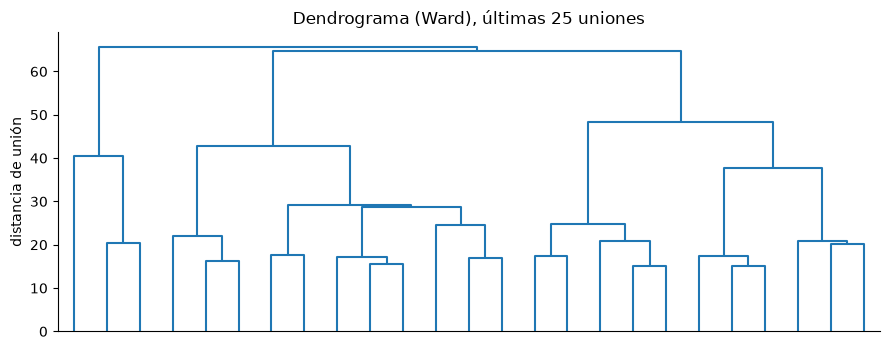

ARI k-means vs jerárquico (k = 5): 0.45


jerárquico,1,2,3,4,5
k-means,,,,,
Adultos mayores estables,1,76,717,19,10
Compromiso respiratorio,52,0,8,0,1
Hipertensión arterial,0,333,151,117,64
Jóvenes con signos estables,1,2,114,800,97
Taquicardia / febril,0,1,92,20,324


In [42]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import DBSCAN
from sklearn.mixture import GaussianMixture

muestra = np.random.default_rng(SEMILLA).choice(len(Z_train), 3000, replace=False)
arbol_ward = linkage(Z_train[muestra], method="ward")
fig, ax = plt.subplots(figsize=(9, 3.6))
dendrogram(arbol_ward, truncate_mode="lastp", p=25, no_labels=True, ax=ax, color_threshold=0)
ax.set_title("Dendrograma (Ward), últimas 25 uniones"); ax.set_ylabel("distancia de unión"); ax.grid(False)
plt.tight_layout(); plt.show()

jerarquico = fcluster(arbol_ward, t=K, criterion="maxclust")
print(f"ARI k-means vs jerárquico (k = {K}): {adjusted_rand_score(kmeans.labels_[muestra], jerarquico):.2f}")
pd.crosstab(train["grupo"].values[muestra], jerarquico, rownames=["k-means"], colnames=["jerárquico"])

### 21.2 · Mezcla de gaussianas (GMM): pertenencia suave
GMM no dice "pertenece al grupo 1": dice "**70 %** grupo 1, **28 %** grupo 2". La iniciamos en los centroides de k-means. Definimos la **zona gris**: pacientes cuya probabilidad máxima es menor a 0,6.

In [43]:
gmm = GaussianMixture(n_components=K, means_init=kmeans.cluster_centers_, random_state=SEMILLA).fit(Z_train)
prob_gmm = gmm.predict_proba(Z_train)
train["zona_gris"] = prob_gmm.max(axis=1) < 0.6
print(f"ARI k-means vs GMM: {adjusted_rand_score(kmeans.labels_, prob_gmm.argmax(axis=1)):.2f}")
print(f"Pacientes en zona gris: {train['zona_gris'].sum()} ({train['zona_gris'].mean():.0%})")
(train.groupby("grupo")["zona_gris"].mean() * 100).round(0).sort_values().to_frame("% en zona gris")

ARI k-means vs GMM: 0.27
Pacientes en zona gris: 1511 (20%)


,% en zona gris
grupo,
Compromiso respiratorio,2.0
Hipertensión arterial,16.0
Taquicardia / febril,19.0
Jóvenes con signos estables,20.0
Adultos mayores estables,26.0


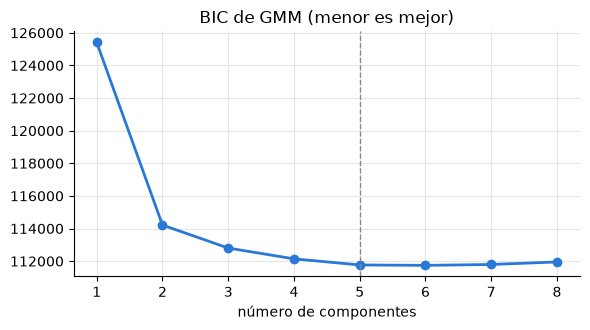

In [44]:
bic = {k: GaussianMixture(n_components=k, n_init=2, random_state=SEMILLA).fit(Z_train).bic(Z_train) for k in range(1, 9)}
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(list(bic), list(bic.values()), marker="o", color=AZUL, lw=2)
ax.axvline(K, color=GRIS, ls="--", lw=1); ax.set_xlabel("número de componentes"); ax.set_title("BIC de GMM (menor es mejor)")
plt.tight_layout(); plt.show()

### 21.3 · DBSCAN: densidad y pacientes atípicos
DBSCAN no pide `k`: un grupo es una región **densa** (al menos `min_samples` vecinos a distancia `eps`), y lo que no cae en ninguna es **ruido** (`-1`). Para elegir `eps` se busca el codo de la distancia al vecino número 12 (2 × 6 variables).

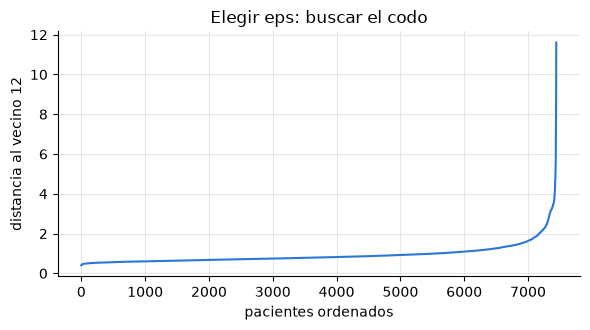

,grupos densos,pacientes ruido,% críticos en el ruido,% críticos en el resto
eps,,,,
0.8,1,2137,29.6,13.8
1.0,1,962,38.3,15.4
1.3,1,439,47.4,16.5
1.6,1,242,55.4,17.1


In [45]:
MIN_MUESTRAS = 12
distancias, _ = NearestNeighbors(n_neighbors=MIN_MUESTRAS).fit(Z_train).kneighbors(Z_train)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(np.sort(distancias[:, -1]), color=AZUL); ax.set_ylabel(f"distancia al vecino {MIN_MUESTRAS}")
ax.set_xlabel("pacientes ordenados"); ax.set_title("Elegir eps: buscar el codo")
plt.tight_layout(); plt.show()

critico_train = (y_train == 0)
filas = []
for eps in [0.8, 1.0, 1.3, 1.6]:
    etiquetas = DBSCAN(eps=eps, min_samples=MIN_MUESTRAS).fit_predict(Z_train)
    ruido = etiquetas == -1
    filas.append({"eps": eps, "grupos densos": len(set(etiquetas) - {-1}), "pacientes ruido": int(ruido.sum()),
                  "% críticos en el ruido": critico_train[ruido].mean() * 100,
                  "% críticos en el resto": critico_train[~ruido].mean() * 100})
pd.DataFrame(filas).set_index("eps").round(1)

In [46]:
atipicos = DBSCAN(eps=1.3, min_samples=MIN_MUESTRAS).fit_predict(Z_train) == -1
train["atipico"] = atipicos
print("Pacientes atípicos (eps = 1,3) por grupo de k-means:")
display(train.groupby("grupo")["atipico"].agg(["sum", "mean"]).rename(columns={"sum": "atípicos", "mean": "proporción"}).round(3))
train.loc[atipicos, VARS_CLUSTER + ["motivo_categoria", "y_triaje"]].head(8)

Pacientes atípicos (eps = 1,3) por grupo de k-means:


,atípicos,proporción
grupo,,
Adultos mayores estables,58,0.028
Compromiso respiratorio,124,0.992
Hipertensión arterial,60,0.037
Jóvenes con signos estables,19,0.008
Taquicardia / febril,178,0.163


,edad,fc,fr,pam,temp_c,spo2,motivo_categoria,y_triaje
26,74.0,145.0,18.0,79.667,36.8,NaN,cardiovascular,2
39,81.0,80.0,20.0,173.333,36.0,98.0,musculoesqueletico,3
46,70.0,96.0,22.0,NaN,36.3,78.0,respiratorio,2
82,32.0,109.0,20.0,89.333,39.8,NaN,fiebre_general,3
92,19.0,110.0,22.0,60.000,36.0,98.0,trauma,3
102,67.0,130.0,20.0,94.333,38.1,NaN,fiebre_general,4
105,90.0,100.0,30.0,51.667,36.0,NaN,respiratorio,2
106,92.0,110.0,26.0,110.000,36.5,88.0,respiratorio,3


### 21.4 · Resumen: por qué k-means para el servicio

| Algoritmo | Necesita `k` | Pertenencia | Atípicos | Qué encontró aquí |
|---|---|---|---|---|
| **K-means** | Sí | Dura | No | 5 perfiles clínicos estables (ARI bootstrap ≈ 0,9) |
| Jerárquico (Ward) | Se corta el árbol | Dura | No | ARI 0,45 con k-means: **acuerdo moderado**. Respiratorio, jóvenes y taquicardia se conservan casi enteros; hipertensión se reparte entre varios |
| GMM | Sí (BIC) | **Suave** | Indirecto | ARI 0,27. El BIC deja de bajar desde k = 5. **Uno de cada cinco pacientes (20 %) está en zona gris**; el respiratorio casi nunca (2 %) |
| DBSCAN | No (pide `eps`) | Dura | **Sí** | Un solo grupo denso con cualquier `eps`: no hay islas separadas. Pero su **ruido son pacientes mucho más graves** |

**Cómo leerlo:**
- Tres métodos con supuestos distintos coinciden solo en parte. Confirma lo que dijo la silueta: los pacientes forman un **continuo**, con perfiles reconocibles en el centro y fronteras borrosas. Es lo normal en datos clínicos (lo mismo pasó con PIMA en la semana 10).
- **DBSCAN y k-means se confirman entre sí:** el 99 % del grupo "Compromiso respiratorio" de k-means son atípicos para DBSCAN. Ese grupo es la "cola" de pacientes con signos extremos.
- **El hallazgo clínico de DBSCAN:** con `eps = 1,3`, el 47 % de los pacientes atípicos es crítico, contra el 17 % del resto. Los signos vitales raros son también peligrosos. Queda como idea para el equipo: marcar a un paciente atípico como "revisar con prioridad".
- **Nos quedamos con k-means** para el servicio: es el más estable, asigna a un paciente nuevo en un instante (`predict`) y sus 5 perfiles tienen lectura clínica. La zona gris de GMM sería una mejora posible: avisar cuando un paciente está entre dos perfiles.

## Bloque 22 · Aumento de datos dentro de cada grupo

Técnica de la semana 9 (la idea de SMOTE): **nuevo = base + u × (vecino − base)**, con `u` al azar entre 0 y 1, buscando el vecino **dentro del mismo grupo y del mismo nivel de triaje** (lo exige R07).

| Decisión | Por qué |
|---|---|
| Las bases salen del **conjunto de prueba** | Si el servicio analiza a los sintéticos, el modelo no verá "casi copias" de su entrenamiento |
| Vecino del **mismo grupo y mismo nivel** | El nuevo cae dentro del perfil clínico y conserva su etiqueta |
| Se interpolan las **8 numéricas** (incluido el dolor) | Sexo, llegada, lesión y motivo se copian de la base: interpolar "media ambulancia" no tiene sentido |
| Los **faltantes** de la base se conservan | En la vida real no a todos se les mide todo |
| Si sale **idéntico** a un paciente real, se repite el sorteo de `u` | Sería una copia de una persona |
| Cada sintético queda **marcado y ligado** | `origen = "sintetico"`, su `cluster` y la fila base |
| Reparto **proporcional** al tamaño de cada grupo, mínimo 10 | El grupo pequeño también tiene sintéticos |

In [47]:
N_SINTETICOS, K_VECINOS = 200, 5
LIMITES = {"edad": (18, 100, 0), "fc": (20, 250, 0), "fr": (4, 80, 0), "pas": (40, 300, 0),
           "pad": (20, 200, 0), "temp_c": (30, 44, 1), "spo2": (50, 100, 0), "dolor_nrs": (0, 10, 0)}


def clave(df):
    return df[NUM].astype(float).round(1).fillna(-999).apply(lambda f: "|".join(map(str, f)), axis=1)


reales = set(clave(d))
base = test.copy()
Z_test = escala_cluster.transform(base[VARS_CLUSTER])
base["cluster"] = kmeans.predict(Z_test)

proporcion = train["cluster"].value_counts(normalize=True).sort_index()
cuota = np.maximum(10, np.round(proporcion * N_SINTETICOS)).astype(int)
cuota.iloc[cuota.argmax()] -= cuota.sum() - N_SINTETICOS

rng = np.random.default_rng(2026)
nuevos = []
for c, n in cuota.items():
    grupo_c = base[base["cluster"] == c]
    for _ in range(n):
        i = rng.choice(grupo_c.index)
        fila = grupo_c.loc[i]
        candidatos = grupo_c[(grupo_c["y_triaje"] == fila["y_triaje"]) & (grupo_c.index != i)]
        if len(candidatos) == 0:
            candidatos = grupo_c[grupo_c.index != i]
        nn = NearestNeighbors(n_neighbors=min(K_VECINOS, len(candidatos))).fit(Z_test[candidatos.index])
        vecino = candidatos.iloc[rng.choice(nn.kneighbors(Z_test[[i]])[1][0])]
        for _intento in range(20):
            u = rng.random()
            nuevo = fila.copy()
            for v in NUM:
                if pd.notna(fila[v]) and pd.notna(vecino[v]):
                    lo, hi, dec = LIMITES[v]
                    nuevo[v] = round(float(np.clip(fila[v] + u * (vecino[v] - fila[v]), lo, hi)), dec)
            if clave(nuevo.to_frame().T).iloc[0] not in reales:
                break
        nuevo["origen"], nuevo["fila_base"], nuevo["u"] = "sintetico", int(i), round(u, 3)
        nuevos.append(nuevo)

sinteticos = pd.DataFrame(nuevos).reset_index(drop=True)
sinteticos[NUM] = sinteticos[NUM].apply(pd.to_numeric)
sinteticos[["y_triaje", "cluster"]] = sinteticos[["y_triaje", "cluster"]].astype(int)
sinteticos["pam"] = (sinteticos["pas"] + 2 * sinteticos["pad"]) / 3
sinteticos["grupo"] = sinteticos["cluster"].map(nombre)
sinteticos["id_sintetico"] = [f"SINT-{k:04d}" for k in range(1, len(sinteticos) + 1)]
sinteticos["grupo"].value_counts()

grupo
Jóvenes con signos estables    62
Adultos mayores estables       56
Hipertensión arterial          43
Taquicardia / febril           29
Compromiso respiratorio        10
Name: count, dtype: int64

## Bloque 23 · ¿Los sintéticos son buenos?

1. **Siguen en su grupo:** si k-means clasifica a cada sintético, ¿lo pone en el grupo de su base?
2. **No son copias** de ningún paciente real.
3. **Conservan el perfil** (medianas por grupo) y **la mezcla de niveles de triaje**.
4. **El modelo los trata como a los reales:** su AUC crítico debe parecerse al de la prueba. Si fuera mucho más alto, los sintéticos serían "demasiado fáciles" y no servirían para demostrar el sistema.

In [48]:
reasignado = kmeans.predict(escala_cluster.transform(sinteticos[VARS_CLUSTER]))
print(f"1. Sintéticos que k-means vuelve a poner en su grupo: {np.mean(reasignado == sinteticos['cluster']):.1%}")
print(f"2. Sintéticos idénticos a un paciente real: {clave(sinteticos).isin(reales).sum()}")
P_sint = modelo_final.predict_proba(sinteticos[PREDICTORES])
print(f"4. AUC crítico del modelo · reales de prueba: {roc_auc_score(real_test, p_crit_test):.3f}"
      f" · sintéticos: {roc_auc_score(sinteticos['y_triaje'] <= 2, P_sint[:, 0]):.3f}")

comparar = pd.concat([
    train.groupby("grupo")[NUM].median().assign(origen="real (train)"),
    sinteticos.groupby("grupo")[NUM].median().assign(origen="sintético"),
]).reset_index().set_index(["grupo", "origen"]).sort_index().round(1)
print("\n3. Medianas por grupo:"); display(comparar)
niveles = pd.DataFrame({"reales (prueba)": base["y_triaje"].value_counts(normalize=True),
                        "sintéticos": sinteticos["y_triaje"].value_counts(normalize=True)}).sort_index()
print("   Niveles de triaje (%):"); display((niveles * 100).round(1))

1. Sintéticos que k-means vuelve a poner en su grupo: 99.5%
2. Sintéticos idénticos a un paciente real: 0
4. AUC crítico del modelo · reales de prueba: 0.765 · sintéticos: 0.761

3. Medianas por grupo:


edad     fc    fr    pas   pad  temp_c  spo2  dolor_nrs
grupo                       origen                                                               
Adultos mayores estables    real (train)  69.0   76.0  18.0  131.0  73.0    36.6  97.0        3.0
                            sintético     67.0   75.5  18.0  132.5  73.5    36.6  98.0        3.0
Compromiso respiratorio     real (train)  56.0  101.0  33.0  130.0  86.0    36.9  88.0        6.0
                            sintético     62.5  110.0  28.0  122.5  90.0    36.8  80.0        8.0
Hipertensión arterial       real (train)  57.0   88.0  18.0  163.0  97.0    36.7  98.0        5.0
                            sintético     55.0   85.0  18.0  157.0  95.0    36.6  98.0        4.0
Jóvenes con signos estables real (train)  31.0   85.0  18.0  127.0  78.0    36.7  99.0        5.0
                            sintético     30.0   88.0  18.0  125.5  77.0    36.7  99.0        5.0
Taquicardia / febril        real (train)  45.0  108.0  18.0  135.0  81.0    37.1  97.0        5.0
                            sintético     56.0  108.0  18.0  140.0  79.0    37.1  98.0        4.0

   Niveles de triaje (%):


,reales (prueba),sintéticos
y_triaje,,
1,1.3,1.0
2,17.0,18.5
3,52.6,52.5
4,25.8,26.5
5,3.2,1.5


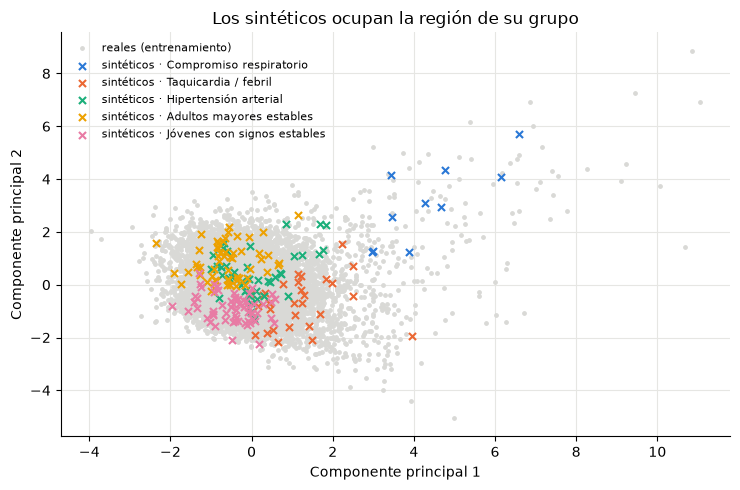

In [49]:
Ps = pca.transform(escala_cluster.transform(sinteticos[VARS_CLUSTER]))
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(XY[:, 0], XY[:, 1], c="#d9d9d6", s=6, label="reales (entrenamiento)")
for grupo in orden:
    m = (sinteticos["grupo"] == grupo).values
    ax.scatter(Ps[m, 0], Ps[m, 1], color=color_de[grupo], s=26, marker="x", label=f"sintéticos · {grupo}")
ax.set_xlabel("Componente principal 1"); ax.set_ylabel("Componente principal 2")
ax.set_title("Los sintéticos ocupan la región de su grupo"); ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

Prácticamente todos los sintéticos quedan en su grupo, ninguno copia a un paciente real, y la mezcla de niveles se conserva. Las medianas del grupo respiratorio son las que más se mueven, porque solo tiene 10 sintéticos. El modelo los ordena con un AUC del mismo orden que en la prueba real: no son más fáciles que los pacientes reales, así que sirven para demostrar el sistema con honestidad.

## Bloque 24 · Guardar los resultados

| Archivo | Para qué |
|---|---|
| `cohorte_sintetica.csv` | Los 200 sintéticos, marcados y ligados a su grupo |
| `clusters.json` | Lo que devuelve el endpoint de clusters de R07 |
| `metricas_modelo.json` | Modelo, umbrales, comparación de modelos, métricas con intervalos y sesgo (README y R22) |

In [50]:
columnas = ["id_sintetico", "origen", "cluster", "grupo", "fila_base", "u"] + NUM + \
           ["sexo", "llegada_ambulancia", "lesion", "motivo_categoria", "y_triaje"]
sinteticos[columnas].to_csv(SALIDA / "cohorte_sintetica.csv", index=False)

descripcion = {
    "Compromiso respiratorio": "Hipoxemia y taquipnea; el grupo más grave",
    "Taquicardia / febril": "Frecuencia cardiaca alta y temperatura algo elevada en adultos (zona de confusión entre crítico y medio)",
    "Adultos mayores estables": "Signos normales; el riesgo viene de la edad y el motivo (zona de confusión entre crítico y medio)",
    "Hipertensión arterial": "Presión arterial elevada sin otros signos de alarma (zona de confusión entre crítico y medio)",
    "Jóvenes con signos estables": "El grupo más grande y menos grave; zona de confusión principal: el modelo subtriaja a sus pocos críticos",
}
d_todo = pd.concat([train, base])
d_todo["cluster"] = kmeans.predict(escala_cluster.transform(d_todo[VARS_CLUSTER]))
clusters_json = {"algoritmo": "k-means", "k": K, "variables": VARS_CLUSTER,
                 "criterio_k": "máximo local de silueta, estabilidad bootstrap (ARI) y grupos clínicamente distintos",
                 "grupos": []}
for c in range(K):
    gc = d_todo[d_todo["cluster"] == c]
    clusters_json["grupos"].append({
        "cluster": c, "nombre": nombre[c], "descripcion": descripcion[nombre[c]],
        "reales": int(len(gc)), "sinteticos": int((sinteticos["cluster"] == c).sum()),
        "pct_critico": round(float((gc["y_triaje"] <= 2).mean() * 100), 1),
        "mediana": {v: round(float(gc[v].median()), 1) for v in NUM}})
(SALIDA / "clusters.json").write_text(json.dumps(clusters_json, ensure_ascii=False, indent=2), encoding="utf-8")

metricas_json = {
    "modelo": "Regresión logística multinomial + 11 signos de alarma clínicos (scikit-learn)",
    "categorias": {"critico": "niveles 1-2", "medio": "nivel 3", "no_critico": "niveles 4-5"},
    "n_entrenamiento": int(len(train)), "n_prueba": int(len(test)),
    "regla": {"U_CRITICO": U_CRITICO, "U_NO_CRITICO": U_NO_CRITICO, "GUARDA": GUARDA, "U_ALERTA": U_ALERTA,
              "red_seguridad": "SpO2 < 88 % o PAS < 90 mmHg"},
    "comparacion_modelos_cv": {n: {c: {"media": round(float(comparacion.loc[n, c]), 3), "desv": round(float(desviacion.loc[n, c]), 3)}
                                   for c in CLAVE + ["sens_critica", "espec_critica", "f1_macro"]} for n in ORDEN},
    "comparacion_modelos_prueba": prueba_modelos.round(3).to_dict(orient="index"),
    "tiempo_entrenamiento_s": {n: round(float(RESULTADOS[n]["tiempo_s"]), 2) for n in ORDEN},
    "prueba": {k: {"valor": round(float(r["valor"]), 3), "ic95": [round(float(r["IC95_bajo"]), 3), round(float(r["IC95_alto"]), 3)]}
               for k, r in resultado_prueba.iterrows()},
    "sesgo": sesgo.round(3).astype({"grupo": str}).to_dict(orient="records"),
}
(SALIDA / "metricas_modelo.json").write_text(json.dumps(metricas_json, ensure_ascii=False, indent=2, default=float),
                                             encoding="utf-8")
print("Guardado en", SALIDA.relative_to(RAIZ))

Guardado en back\preprocesamiento\salida_ia


## Bloque 25 · Cierre

| Decisión | Valor | Dónde se usa |
|---|---|---|
| Qué predice | Crítico (1-2), medio (3), no crítico (4-5); el médico acepta o rechaza | Reporte pendiente de aprobación (R10) |
| Modelo | Regresión logística + 11 signos de alarma, elegida entre 5 modelos entrenados por separado y comparados a igual sensibilidad | Servicio `ml` |
| Datos al modelo | 12 variables clínicas, sin datos personales ni indicadores de faltante | Capa de seudonimización (R12) |
| Crítico | P(crítico) ≥ `U_CRITICO` (detecta ≥ 70 % de los críticos) o red de seguridad | Reporte (R10) |
| No crítico | P(no crítico) ≥ `U_NO_CRITICO` y P(crítico) < `GUARDA` | Reporte (R10) |
| Alerta en vivo | P(crítico) ≥ `U_ALERTA` (VPP ≥ 0,50) o red de seguridad | Alerta con reconocimiento (R20) |
| Grupos | k-means, k = 5, sobre edad, FC, FR, PAM, temperatura y SpO2 | Endpoint de clusters (R07) |
| Aumento | 200 sintéticos desde prueba, dentro de cada grupo y nivel | Cohorte del sistema (R07) |

### Pendiente con el biomédico
1. Validar las **tres categorías**, los **cortes de las alarmas** y la **red de seguridad**.
2. Validar los criterios de los **umbrales** (70 % de sensibilidad para crítico; VPP ≥ 0,50 para la alerta).
3. Revisar los **nombres e interpretación** de los cinco grupos.
4. Completar `docs/DATASETS.md`.

### Ética y normativa
- **Apoyo, no decisión.** La categoría no entra a la historia clínica hasta que el médico la acepta (R10).
- **Datos sensibles** (Ley 1581 de 2012): al modelo solo le llegan variables clínicas y un seudónimo (R12).
- **Validación local:** el modelo se entrenó con pacientes de Corea y EE. UU. Antes de usarlo con pacientes colombianos habría que validarlo localmente, por subgrupos.